<a href="https://www.kaggle.com/code/lalit7881/caffeine-anxiety-analysis-eda-78-5?scriptVersionId=372466391" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/samartalwar/caffeine-crash-and-jitters-energy-drinks-and-anxiety/caffeine_crash_and_anxiety_telemetry.csv


## Import libraries

In [2]:
from pathlib import Path
import warnings
import re

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
%matplotlib inline

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
RANDOM_STATE = 42

# Discover data dynamically so the notebook works in local and Kaggle environments.
DATA_ROOTS = [
    Path('.'),
    Path('/kaggle/input'),
    Path('/kaggle/input'),
    Path('/kaggle/input/datasets'),
]

def resolve_data_file(file_name=None, suffixes=None):
    """Resolve a data file from common notebook data roots."""
    suffixes = tuple(suffixes or [])
    for root in DATA_ROOTS:
        if not root.exists():
            continue
        matches = [path for path in root.rglob('*') if path.is_file()]
        if file_name:
            exact_matches = [path for path in matches if path.name == file_name]
            if exact_matches:
                return exact_matches[0]
        if suffixes:
            typed_matches = [path for path in matches if path.suffix.lower() in suffixes]
            if typed_matches:
                return typed_matches[0]
    raise FileNotFoundError(f'Could not resolve data file: {file_name or suffixes}')

data_path = resolve_data_file(
    file_name='caffeine_crash_and_anxiety_telemetry.csv',
    suffixes=['.csv']
)
print(f'Loading data from: {data_path}')
df_raw = pd.read_csv(data_path)
display(df_raw.head())

Loading data from: /kaggle/input/datasets/samartalwar/caffeine-crash-and-jitters-energy-drinks-and-anxiety/caffeine_crash_and_anxiety_telemetry.csv


,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.400,7.000,2.290,Brewed Drip Coffee,138,8.700,36,2.000,1.000,1.000,7.500,4.100,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.100,7.100,2.410,Energy Drink (Sugar-Free),164,0.000,3,2.400,2.000,5.500,7.500,2.500,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.900,5.100,2.070,Energy Drink (Full Sugar),179,36.900,10,3.800,4.800,5.500,3.600,7.900,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.800,5.000,2.340,Pre-Workout Supplement,408,1.600,3,6.800,4.200,7.300,7.500,10.000,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.000,6.300,1.920,Energy Drink (Full Sugar),170,50.200,11,2.000,2.000,1.100,2.600,10.000,Severe Crash & Tachycardia


In [3]:
print(f'Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]:,} columns')
df_raw.info()

quality_report = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_n': df_raw.isna().sum(),
    'missing_pct': (df_raw.isna().mean() * 100).round(2),
    'unique_n': df_raw.nunique(dropna=True),
    'sample_value': [
        df_raw[column].dropna().iloc[0] if df_raw[column].notna().any() else np.nan
        for column in df_raw.columns
    ],
}).sort_values(['missing_pct', 'unique_n'], ascending=[False, False])
display(quality_report)

print(f'Exact duplicate rows: {df_raw.duplicated().sum():,}')
display(df_raw.describe(include=[np.number]).T)

# Check object columns for date-like values. High-cardinality values are skipped,
# because identifiers can be accidentally parseable and are not dates in disguise.
date_like_columns = []
for column in df_raw.select_dtypes(include='object').columns:
    values = df_raw[column].dropna()
    if values.empty or values.nunique() > max(100, len(df_raw) * 0.8):
        continue
    parsed = pd.to_datetime(values, errors='coerce')
    if parsed.notna().mean() >= 0.80:
        date_like_columns.append(column)

print('Inferred date-like columns:', date_like_columns if date_like_columns else 'None detected')

Dataset shape: 8,000 rows × 18 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   object 
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   object 
 3   cyp1a2_metabolizer_type   8000 non-null   object 
 4   caffeine_tolerance        8000 non-null   object 
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   object 
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score 

,dtype,missing_n,missing_pct,unique_n,sample_value
user_id,object,0,0.000,8000,CAF-00001
sugar_grams,float64,0,0.000,617,8.700
daily_hydration_liters,float64,0,0.000,381,2.290
caffeine_mg,int64,0,0.000,375,138
heart_rate_spike_bpm,float64,0,0.000,225,2.000
consumption_duration_min,int64,0,0.000,96,36
jitters_intensity_score,float64,0,0.000,91,1.000
acute_anxiety_score,float64,0,0.000,91,1.000
crash_severity_score,float64,0,0.000,91,4.100
baseline_anxiety_score,float64,0,0.000,86,2.400


Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,"8,000.000",32.951,11.514,18.000,24.000,30.000,40.000,65.000
baseline_anxiety_score,"8,000.000",3.489,2.079,1.000,1.800,3.000,4.600,9.500
prior_sleep_hours,"8,000.000",6.376,1.293,3.200,5.500,6.400,7.300,9.500
daily_hydration_liters,"8,000.000",2.108,0.784,0.600,1.560,2.110,2.650,4.800
caffeine_mg,"8,000.000",198.044,65.866,40.000,157.000,195.000,234.000,420.000
sugar_grams,"8,000.000",18.026,19.132,0.000,0.800,10.500,34.600,62.000
consumption_duration_min,"8,000.000",28.976,20.489,3.000,10.000,26.000,45.000,107.000
heart_rate_spike_bpm,"8,000.000",4.670,4.004,2.000,2.000,2.500,6.200,35.700
jitters_intensity_score,"8,000.000",3.323,2.310,1.000,1.300,2.700,4.500,10.000
acute_anxiety_score,"8,000.000",3.684,2.371,1.000,1.700,3.200,5.100,10.000


Inferred date-like columns: None detected


In [4]:
df_raw.describe()

,age,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score
count,"8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000","8,000.000"
mean,32.951,3.489,6.376,2.108,198.044,18.026,28.976,4.670,3.323,3.684,5.649,6.294
std,11.514,2.079,1.293,0.784,65.866,19.132,20.489,4.004,2.310,2.371,1.395,2.335
min,18.000,1.000,3.200,0.600,40.000,0.000,3.000,2.000,1.000,1.000,1.500,1.000
25%,24.000,1.800,5.500,1.560,157.000,0.800,10.000,2.000,1.300,1.700,4.500,4.600
50%,30.000,3.000,6.400,2.110,195.000,10.500,26.000,2.500,2.700,3.200,5.700,6.400
75%,40.000,4.600,7.300,2.650,234.000,34.600,45.000,6.200,4.500,5.100,6.900,8.100
max,65.000,9.500,9.500,4.800,420.000,62.000,107.000,35.700,10.000,10.000,7.500,10.000


In [5]:
df_raw.isnull().sum()

user_id                     0
age                         0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
primary_caffeine_source     0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
heart_rate_spike_bpm        0
jitters_intensity_score     0
acute_anxiety_score         0
crash_onset_hours           0
crash_severity_score        0
crash_risk_level            0
dtype: int64

In [6]:
df_raw.duplicated().sum()

np.int64(0)

In [7]:
df_raw.columns

Index(['user_id', 'age', 'gender', 'cyp1a2_metabolizer_type',
       'caffeine_tolerance', 'baseline_anxiety_score', 'prior_sleep_hours',
       'daily_hydration_liters', 'primary_caffeine_source', 'caffeine_mg',
       'sugar_grams', 'consumption_duration_min', 'heart_rate_spike_bpm',
       'jitters_intensity_score', 'acute_anxiety_score', 'crash_onset_hours',
       'crash_severity_score', 'crash_risk_level'],
      dtype='object')

## EDA

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.400,7.000,2.290,Brewed Drip Coffee,138,8.700,36,2.000,1.000,1.000,7.500,4.100,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.100,7.100,2.410,Energy Drink (Sugar-Free),164,0.000,3,2.400,2.000,5.500,7.500,2.500,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.900,5.100,2.070,Energy Drink (Full Sugar),179,36.900,10,3.800,4.800,5.500,3.600,7.900,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.800,5.000,2.340,Pre-Workout Supplement,408,1.600,3,6.800,4.200,7.300,7.500,10.000,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.000,6.300,1.920,Energy Drink (Full Sugar),170,50.200,11,2.000,2.000,1.100,2.600,10.000,Severe Crash & Tachycardia



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   object 
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   object 
 3   cyp1a2_metabolizer_type   8000 non-null   object 
 4   caffeine_tolerance        8000 non-null   object 
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   object 
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,8000,8000,CAF-07984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"8,000.000",NaN,NaN,NaN,32.951,11.514,18.000,24.000,30.000,40.000,65.000
gender,8000,3,Male,3972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cyp1a2_metabolizer_type,8000,3,Normal,3702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
caffeine_tolerance,8000,3,Moderate,3963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseline_anxiety_score,"8,000.000",NaN,NaN,NaN,3.489,2.079,1.000,1.800,3.000,4.600,9.500
prior_sleep_hours,"8,000.000",NaN,NaN,NaN,6.376,1.293,3.200,5.500,6.400,7.300,9.500
daily_hydration_liters,"8,000.000",NaN,NaN,NaN,2.108,0.784,0.600,1.560,2.110,2.650,4.800
primary_caffeine_source,8000,6,Brewed Drip Coffee,2057,NaN,NaN,NaN,NaN,NaN,NaN,NaN
caffeine_mg,"8,000.000",NaN,NaN,NaN,198.044,65.866,40.000,157.000,195.000,234.000,420.000



DATASET COLUMNS
['user_id', 'age', 'gender', 'cyp1a2_metabolizer_type', 'caffeine_tolerance', 'baseline_anxiety_score', 'prior_sleep_hours', 'daily_hydration_liters', 'primary_caffeine_source', 'caffeine_mg', 'sugar_grams', 'consumption_duration_min', 'heart_rate_spike_bpm', 'jitters_intensity_score', 'acute_anxiety_score', 'crash_onset_hours', 'crash_severity_score', 'crash_risk_level']

MISSING VALUES


user_id                     0
age                         0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
primary_caffeine_source     0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
heart_rate_spike_bpm        0
jitters_intensity_score     0
acute_anxiety_score         0
crash_onset_hours           0
crash_severity_score        0
crash_risk_level            0
dtype: int64


DUPLICATE VALUES
0

UNIQUE VALUES


user_id                     8000
age                           48
gender                         3
cyp1a2_metabolizer_type        3
caffeine_tolerance             3
baseline_anxiety_score        86
prior_sleep_hours             64
daily_hydration_liters       381
primary_caffeine_source        6
caffeine_mg                  375
sugar_grams                  617
consumption_duration_min      96
heart_rate_spike_bpm         225
jitters_intensity_score       91
acute_anxiety_score           91
crash_onset_hours             61
crash_severity_score          91
crash_risk_level               4
dtype: int64

NUMERICAL COLUMNS: ['age', 'baseline_anxiety_score', 'prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg', 'sugar_grams', 'consumption_duration_min', 'heart_rate_spike_bpm', 'jitters_intensity_score', 'acute_anxiety_score', 'crash_onset_hours', 'crash_severity_score']

CATEGORICAL COLUMNS: ['user_id', 'gender', 'cyp1a2_metabolizer_type', 'caffeine_tolerance', 'primary_caffeine_source', 'crash_risk_level']


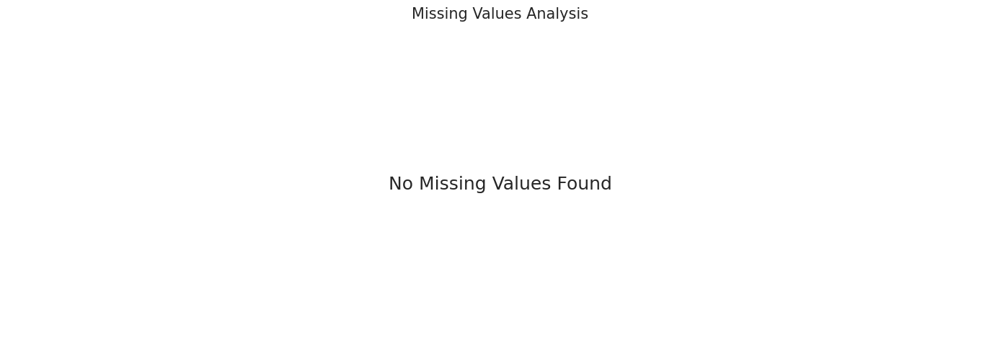

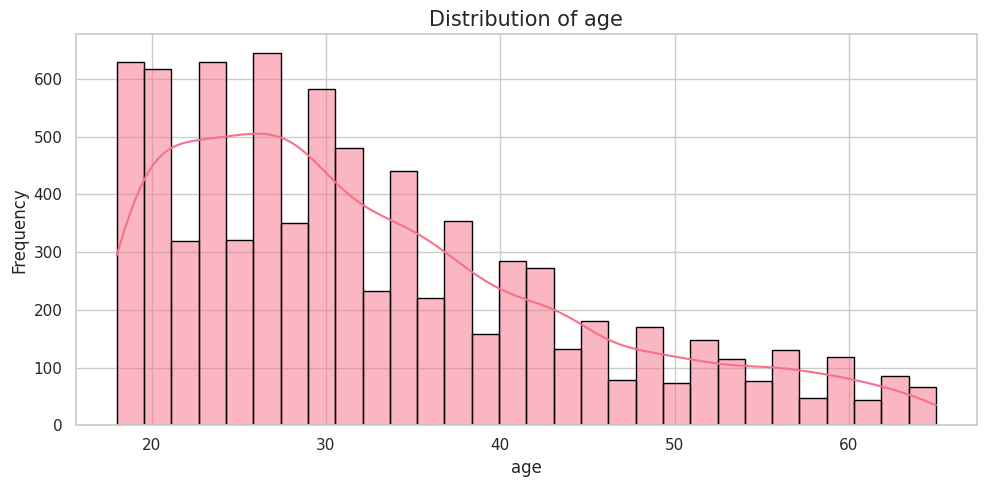

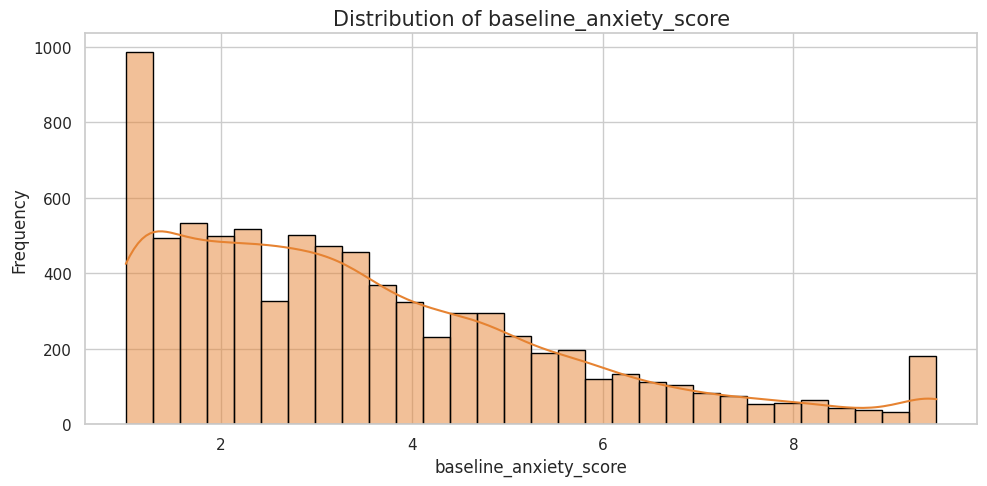

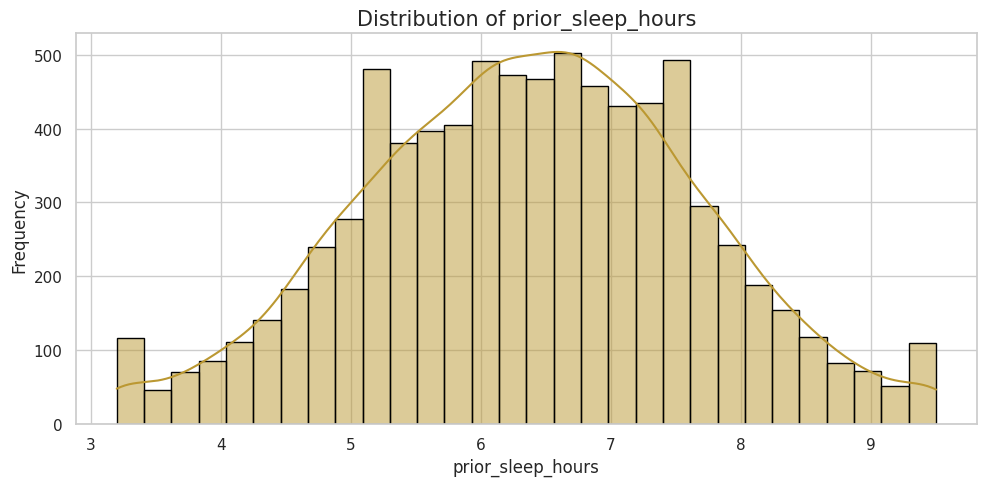

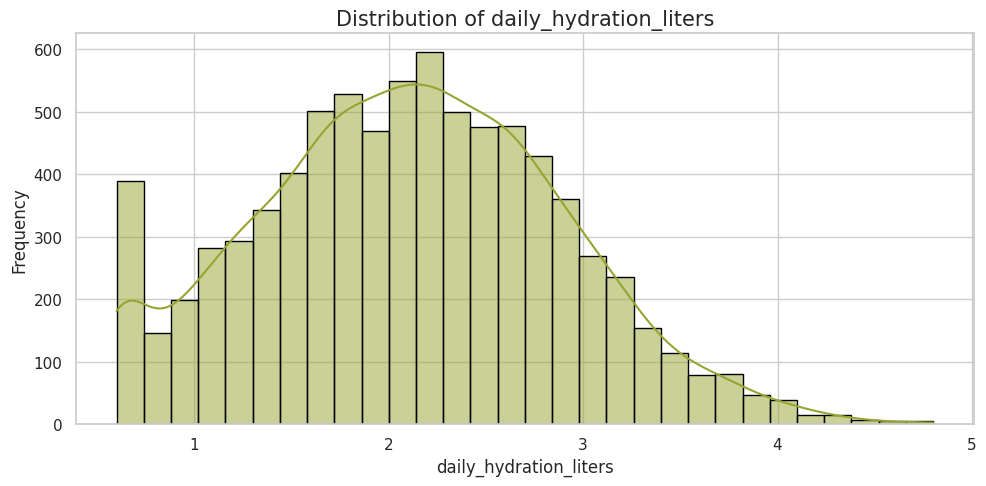

...

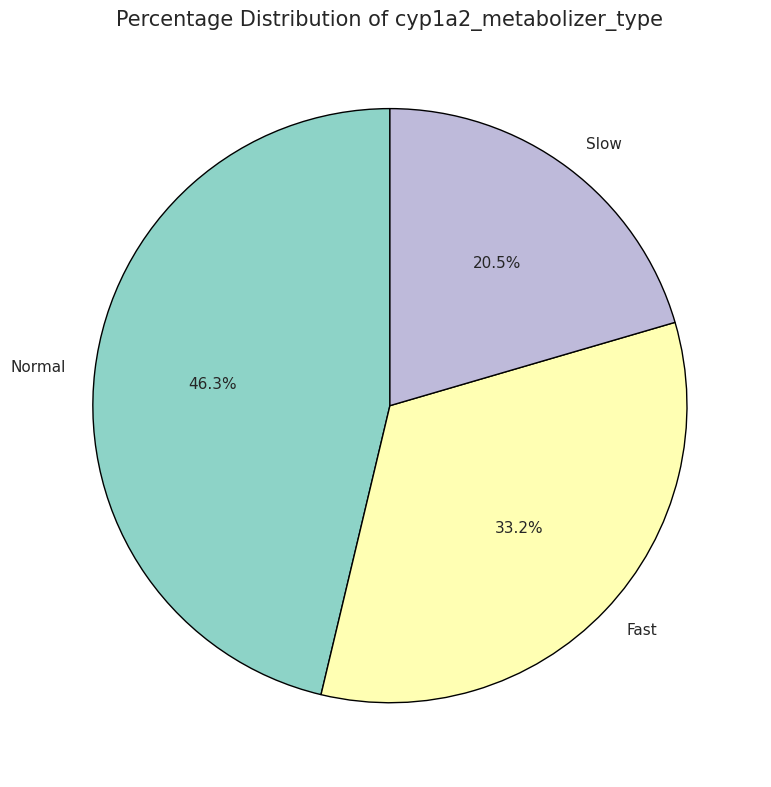

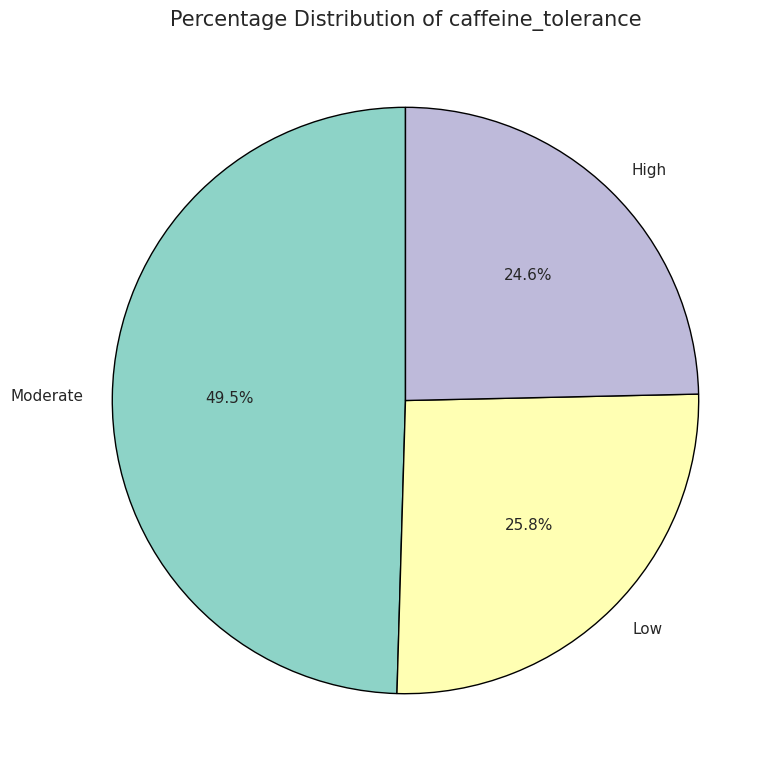

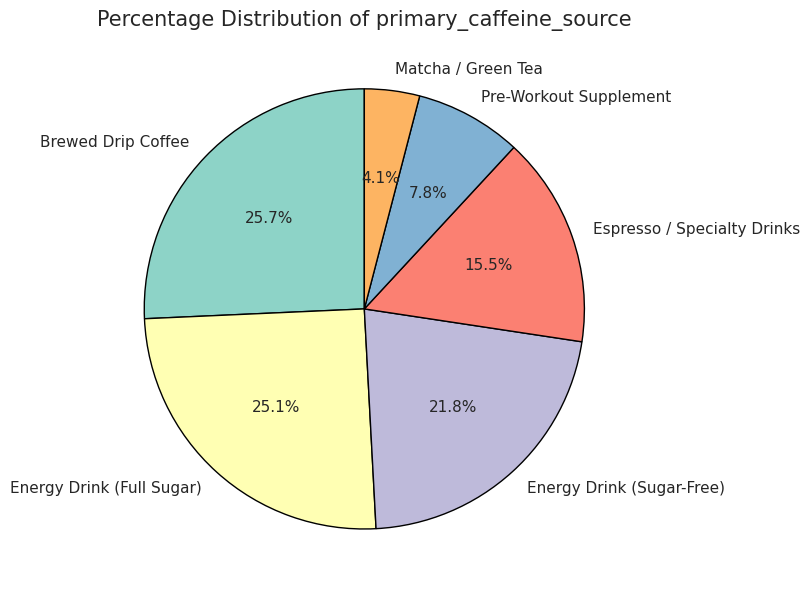

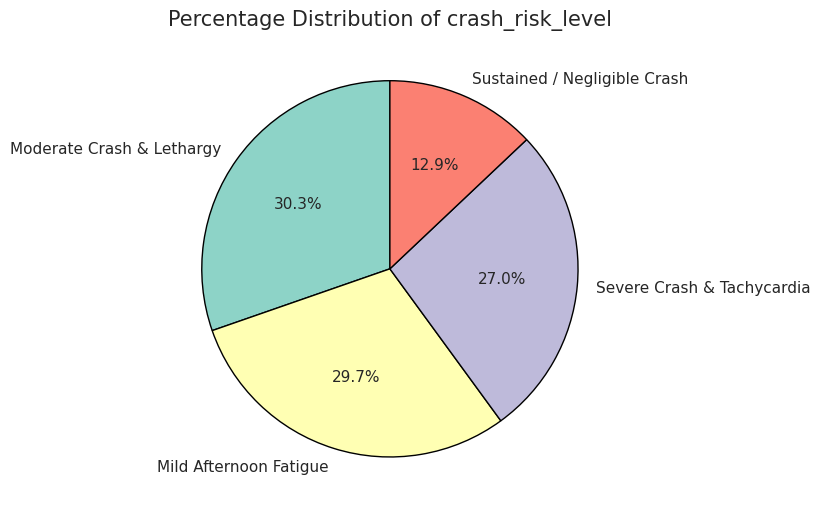

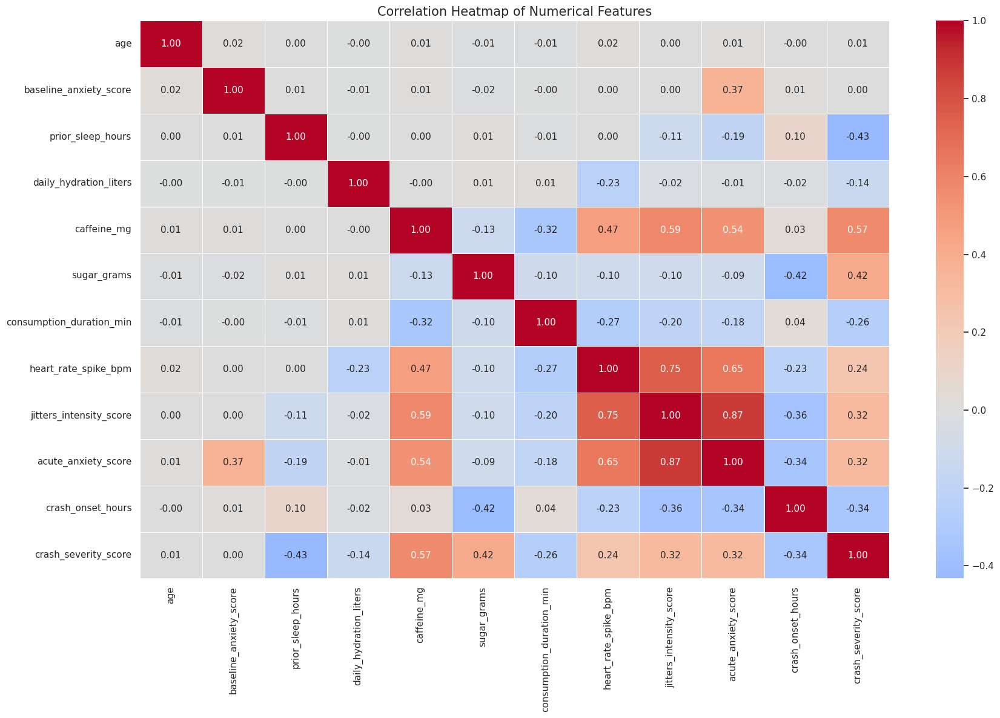

TOP CORRELATION PAIRS


,Feature 1,Feature 2,Correlation,Absolute Correlation
60,jitters_intensity_score,acute_anxiety_score,0.873,0.873
56,heart_rate_spike_bpm,jitters_intensity_score,0.749,0.749
57,heart_rate_spike_bpm,acute_anxiety_score,0.648,0.648
41,caffeine_mg,jitters_intensity_score,0.586,0.586
44,caffeine_mg,crash_severity_score,0.574,0.574
42,caffeine_mg,acute_anxiety_score,0.536,0.536
40,caffeine_mg,heart_rate_spike_bpm,0.470,0.470
29,prior_sleep_hours,crash_severity_score,-0.433,0.433
49,sugar_grams,crash_onset_hours,-0.419,0.419
50,sugar_grams,crash_severity_score,0.417,0.417


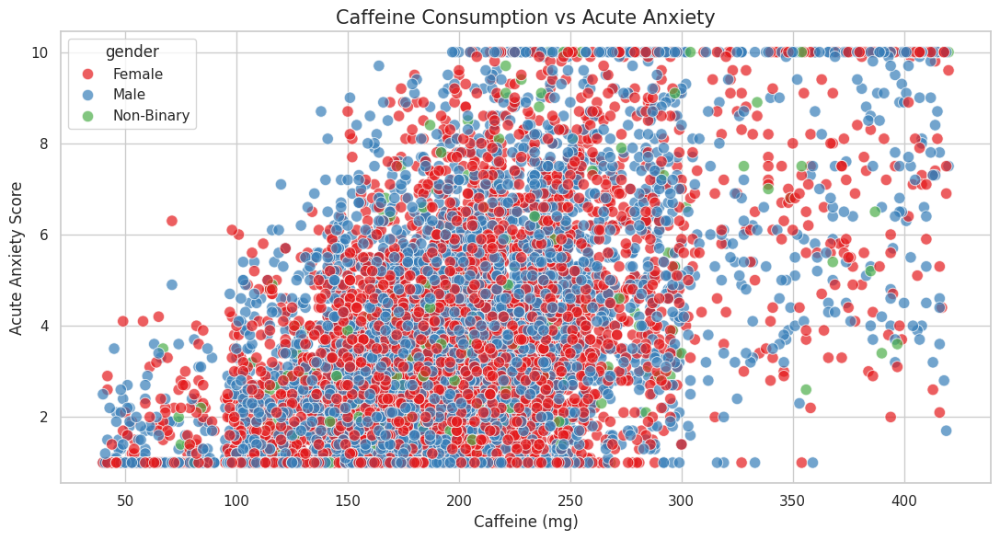

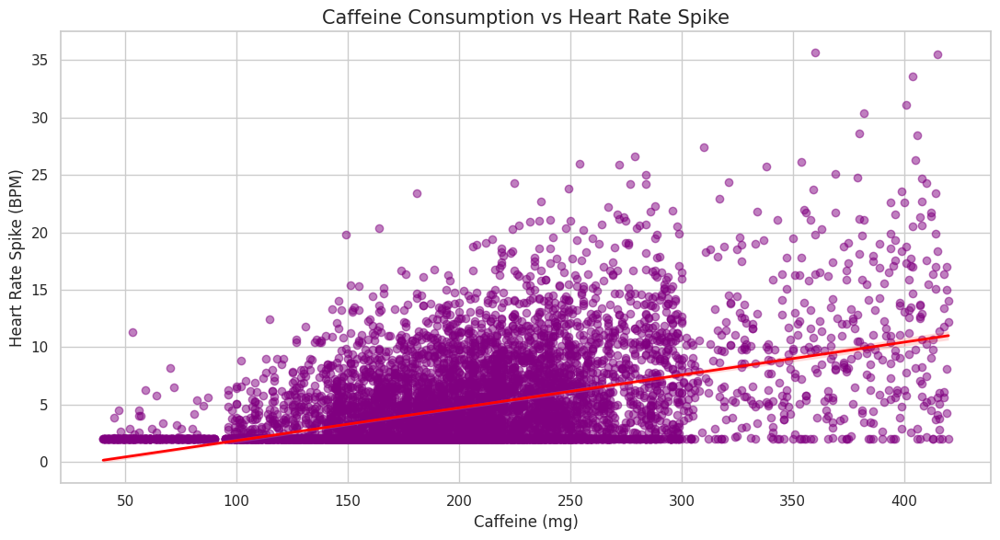

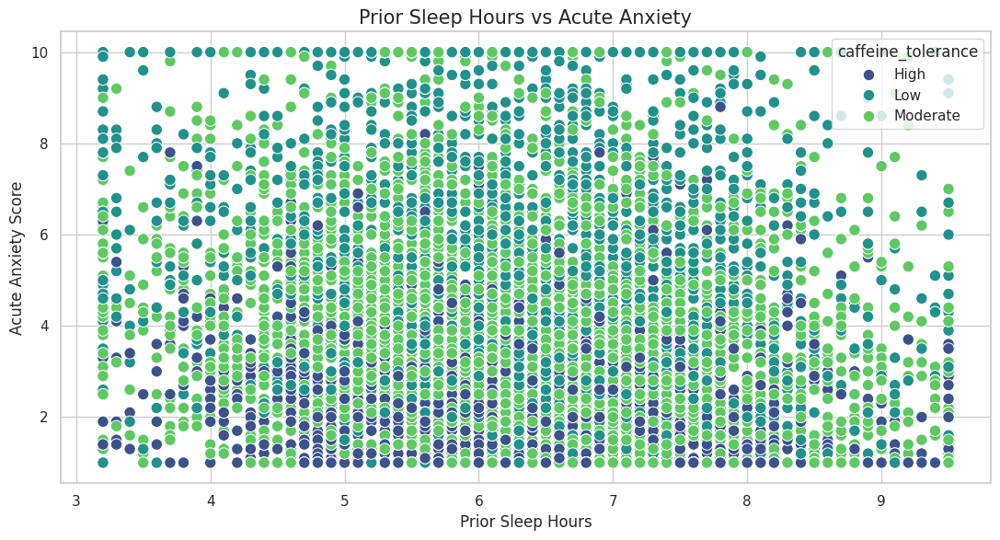

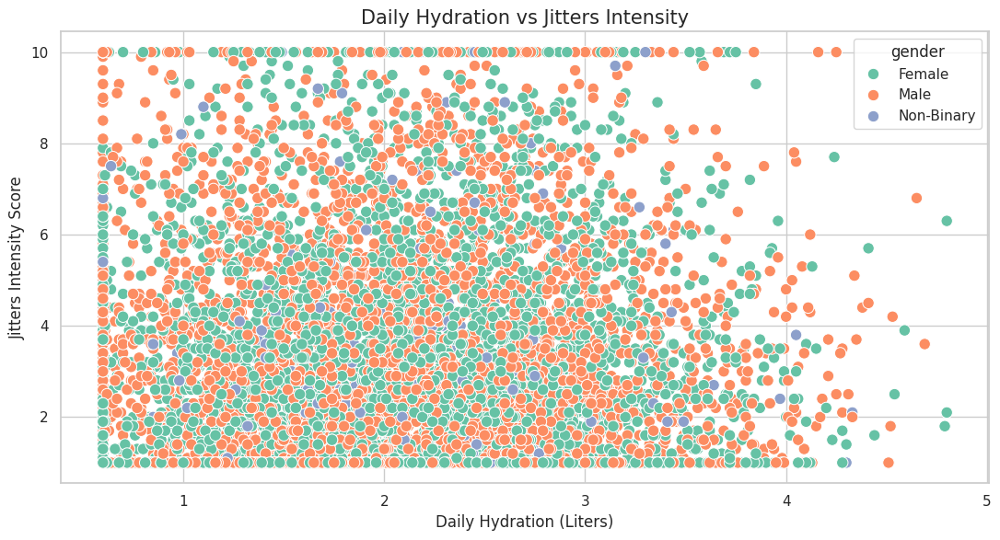

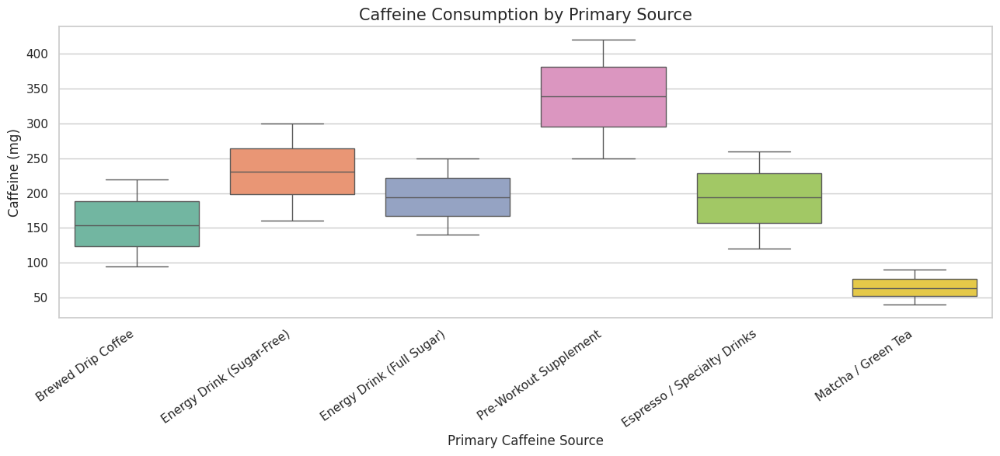

...

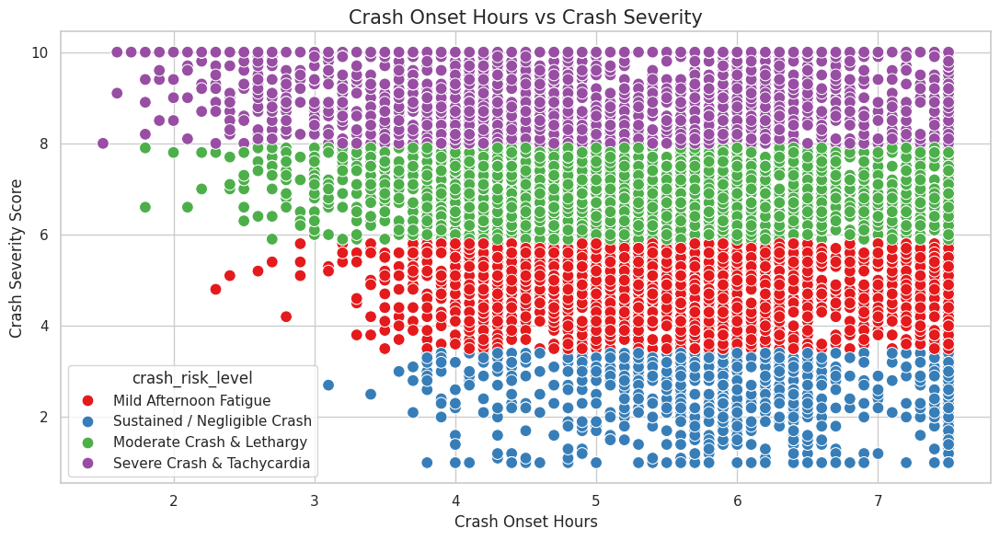

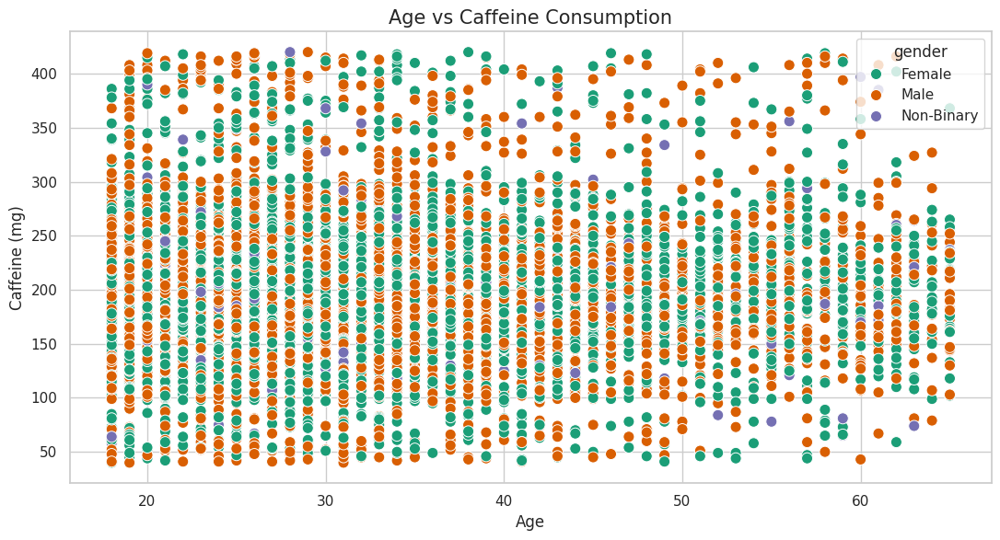

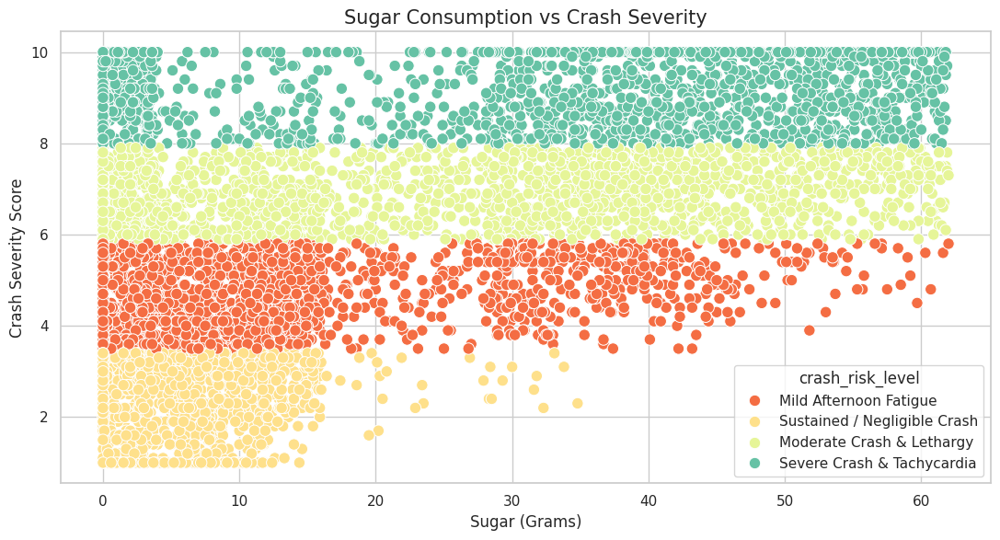

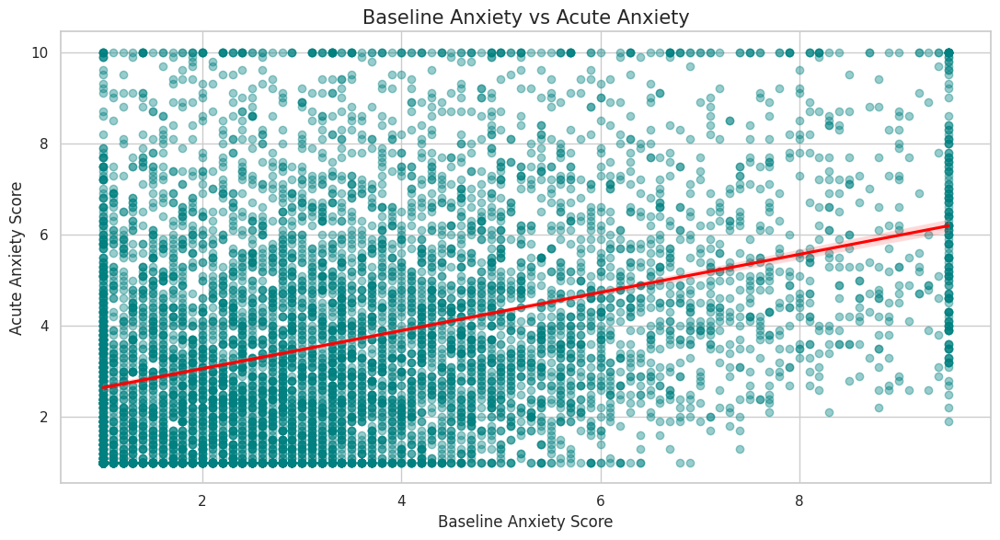

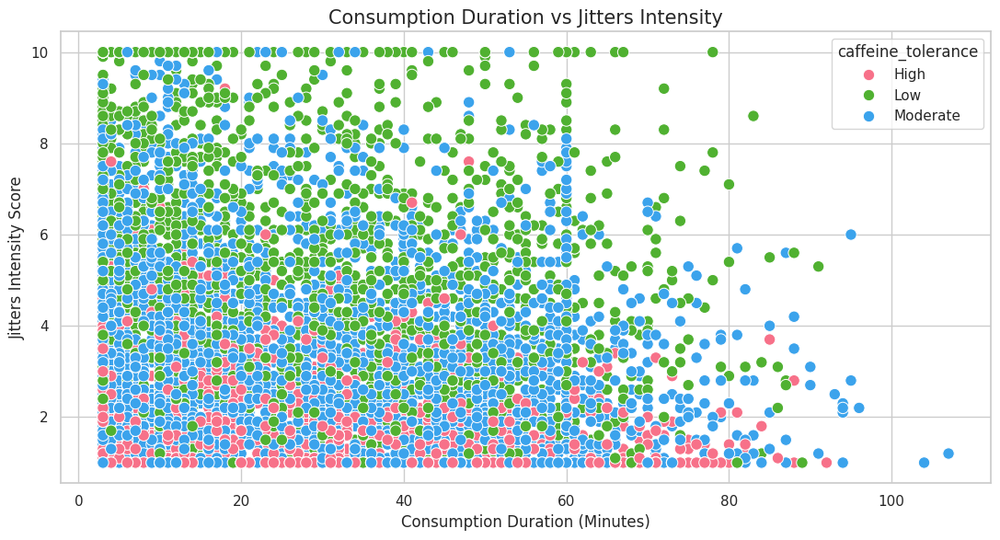

GENDER-WISE AVERAGE ANALYSIS


,caffeine_mg,acute_anxiety_score,heart_rate_spike_bpm,jitters_intensity_score,crash_severity_score
gender,,,,,
Female,198.060,3.671,4.576,3.294,6.315
Male,197.897,3.695,4.741,3.344,6.270
Non-Binary,200.303,3.700,4.981,3.454,6.375


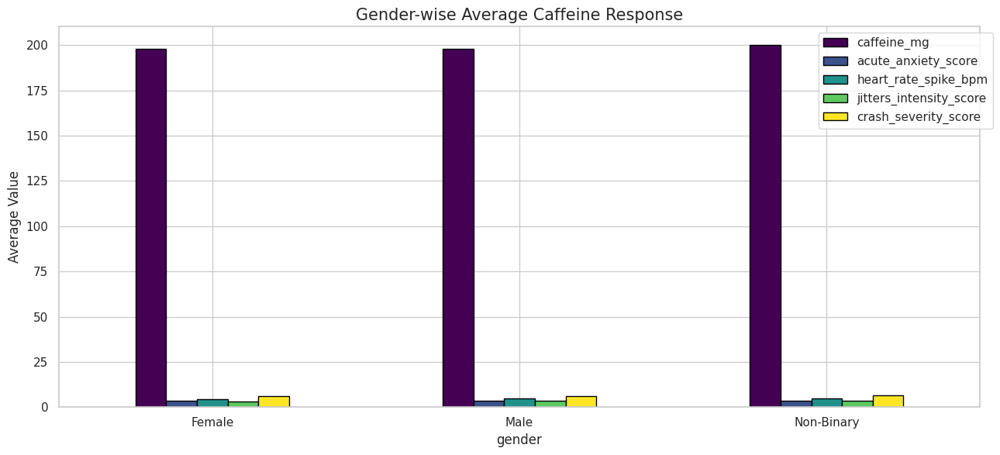

CYP1A2 METABOLIZER ANALYSIS


,caffeine_mg,heart_rate_spike_bpm,acute_anxiety_score,crash_severity_score
cyp1a2_metabolizer_type,,,,
Fast,197.074,3.284,2.552,5.959
Normal,197.852,4.664,3.729,6.322
Slow,200.053,6.933,5.418,6.775


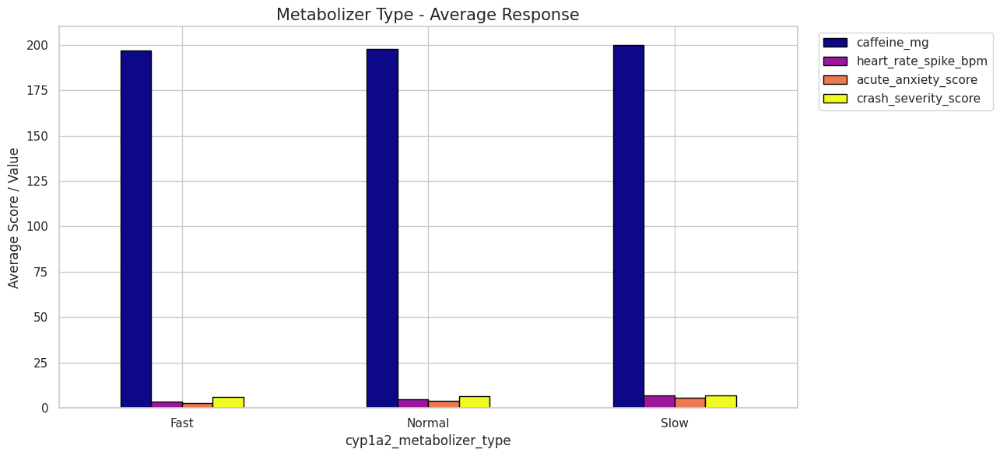

,caffeine_mg,jitters_intensity_score,acute_anxiety_score,heart_rate_spike_bpm,crash_severity_score
caffeine_tolerance,,,,,
High,197.779,1.798,2.229,2.950,7.414
Low,196.175,5.024,5.283,6.806,5.533
Moderate,199.150,3.196,3.574,4.412,6.133


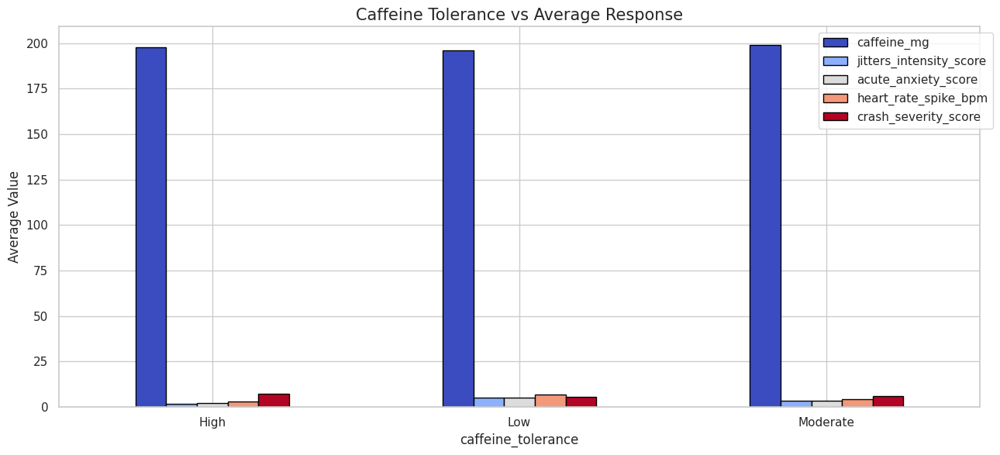

CRASH RISK WISE ANALYSIS


,caffeine_mg,sugar_grams,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_severity_score
crash_risk_level,,,,,,
Mild Afternoon Fatigue,178.436,11.696,3.988,2.928,3.248,4.754
Moderate Crash & Lethargy,208.189,20.083,5.151,3.652,4.004,6.874
Severe Crash & Tachycardia,241.310,28.357,5.719,4.092,4.494,9.188
Sustained / Negligible Crash,129.028,6.184,2.916,1.857,2.242,2.433


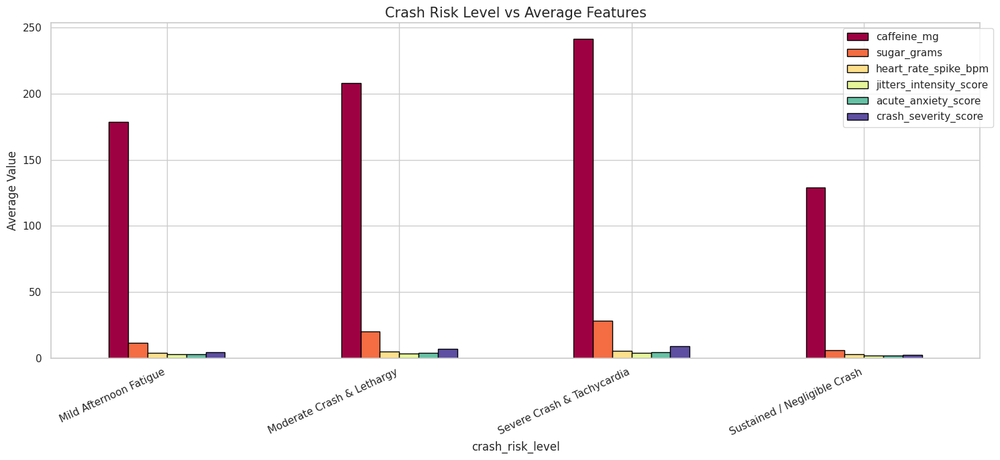

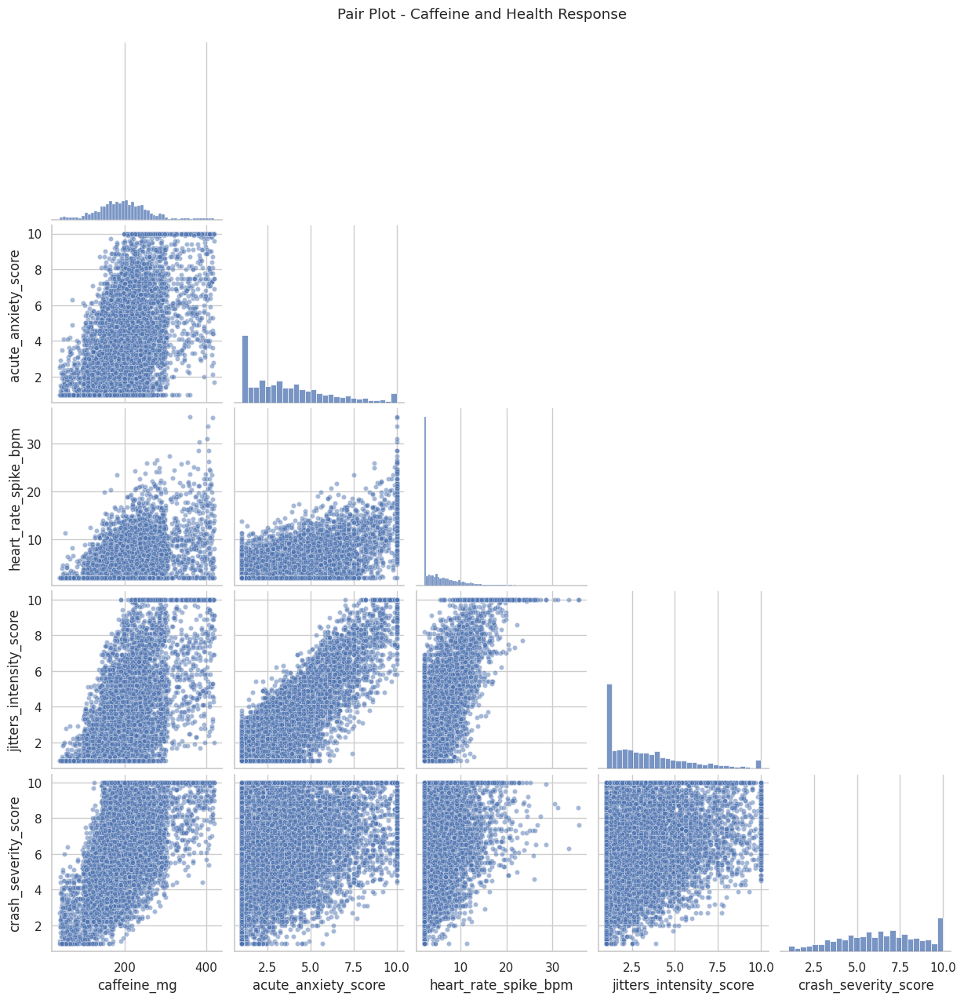

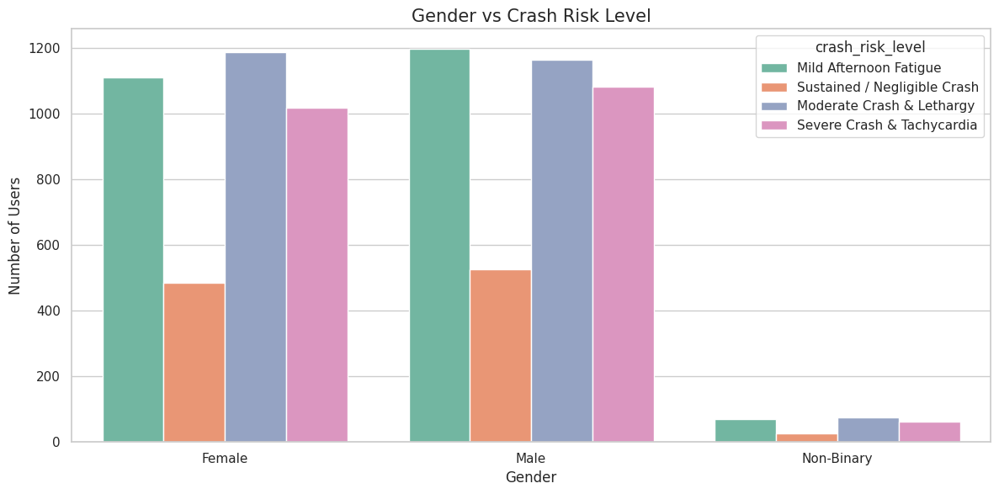

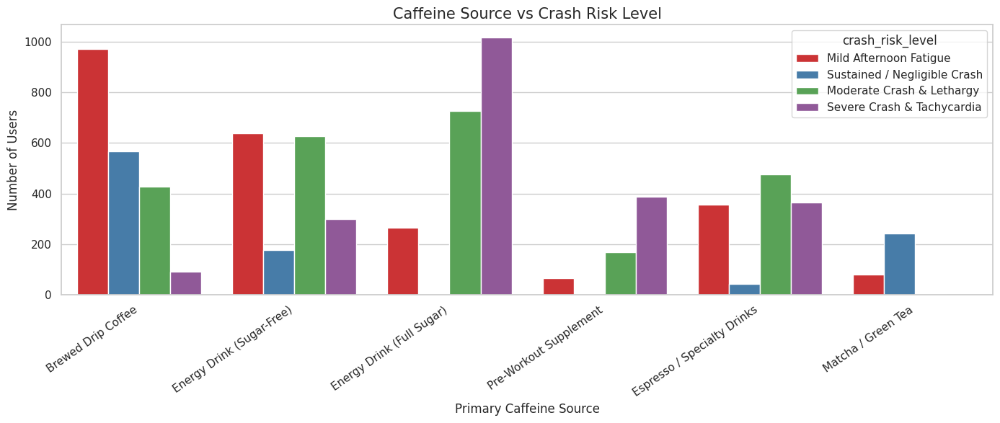

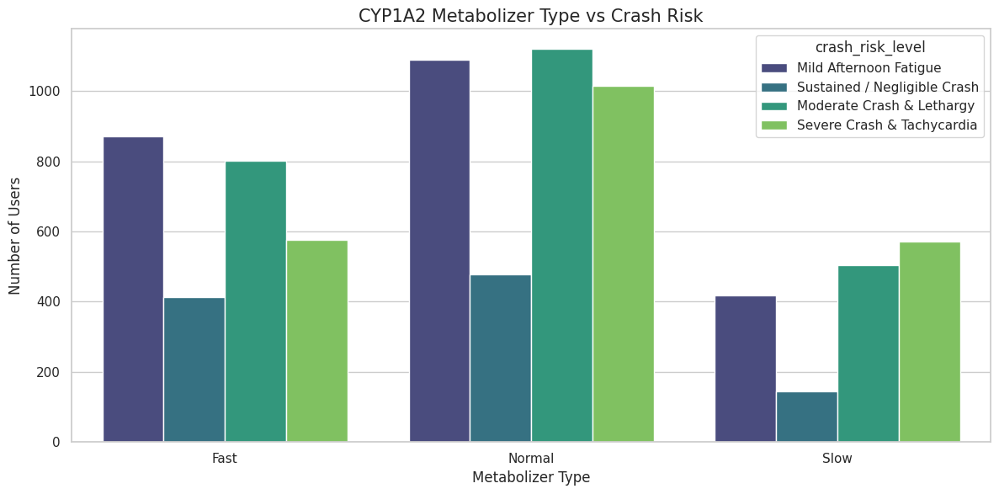

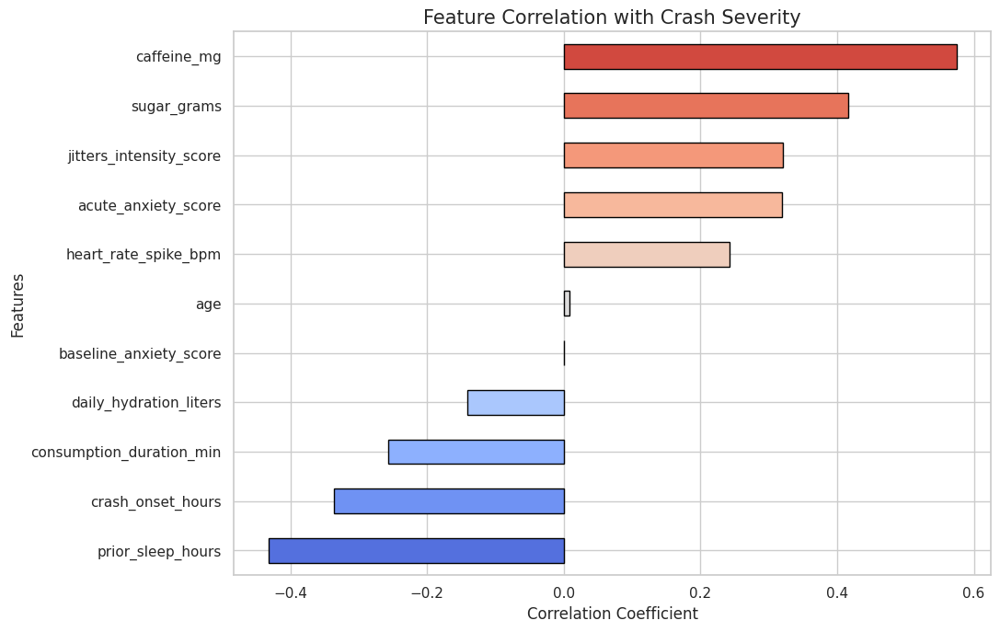


              FINAL EDA REPORT
Total Records: 8000
Total Features: 18
Numerical Features: 12
Categorical Features: 6
Missing Values: 0
Duplicate Records: 0
Unique Users: 8000

CRASH RISK DISTRIBUTION


crash_risk_level
Moderate Crash & Lethargy       2426
Mild Afternoon Fatigue          2377
Severe Crash & Tachycardia      2161
Sustained / Negligible Crash    1036
Name: count, dtype: int64


AVERAGE CAFFEINE CONSUMPTION
198.04 mg

AVERAGE ACUTE ANXIETY SCORE
3.68

AVERAGE HEART RATE SPIKE
4.67 BPM

AVERAGE CRASH SEVERITY
6.29

       COMPLETE EDA VISUALIZATION FINISHED


In [8]:

sns.set_style('whitegrid')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 15


display(df_raw.head())

# ================================================================
# 3. DATASET OVERVIEW
# ================================================================

print("\nDATASET INFORMATION")
df_raw.info()

print("\nSTATISTICAL SUMMARY")
display(df_raw.describe(include='all').T)

print("\nDATASET COLUMNS")
print(df_raw.columns.tolist())

print("\nMISSING VALUES")
display(df_raw.isnull().sum())

print("\nDUPLICATE VALUES")
print(df_raw.duplicated().sum())

print("\nUNIQUE VALUES")
display(df_raw.nunique())

# ================================================================
# 4. SEPARATE NUMERICAL AND CATEGORICAL COLUMNS
# ================================================================

num_cols = df_raw.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = df_raw.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Remove user ID if included in any analysis
if 'user_id' in num_cols:
    num_cols.remove('user_id')

print("NUMERICAL COLUMNS:", num_cols)
print("\nCATEGORICAL COLUMNS:", cat_cols)

# ================================================================
# 5. MISSING VALUES VISUALIZATION
# ================================================================

plt.figure(figsize=(14, 5))

missing_values = df_raw.isnull().sum()

missing_values = missing_values[missing_values > 0]

if len(missing_values) > 0:

    missing_values.sort_values().plot(
        kind='bar',
        color='tomato',
        edgecolor='black'
    )

    plt.title("Missing Values in Dataset")
    plt.xlabel("Columns")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45)

else:
    plt.text(
        0.5, 0.5,
        "No Missing Values Found",
        ha='center',
        va='center',
        fontsize=18
    )

    plt.title("Missing Values Analysis")
    plt.axis('off')

plt.tight_layout()
plt.show()

# ================================================================
# 6. NUMERICAL FEATURES HISTOGRAM
# ================================================================

colors = sns.color_palette(
    'husl',
    len(num_cols)
)

for i, col in enumerate(num_cols):

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df_raw,
        x=col,
        kde=True,
        bins=30,
        color=colors[i],
        edgecolor='black'
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

# ================================================================
# 7. NUMERICAL FEATURES KDE PLOTS
# ================================================================

for col in num_cols:

    plt.figure(figsize=(10, 5))

    sns.kdeplot(
        data=df_raw,
        x=col,
        fill=True,
        color='darkcyan',
        linewidth=2
    )

    plt.title(f"KDE Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

# ================================================================
# 8. NUMERICAL FEATURES BOXPLOTS
# ================================================================

for col in num_cols:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=df_raw,
        x=col,
        color='skyblue',
        linewidth=1.5
    )

    plt.title(f"Boxplot Analysis of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

# ================================================================
# 9. NUMERICAL FEATURES VIOLIN PLOTS
# ================================================================

for col in num_cols:

    plt.figure(figsize=(9, 5))

    sns.violinplot(
        data=df_raw,
        y=col,
        color='orchid',
        inner='quartile'
    )

    plt.title(f"Violin Plot of {col}")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

# ================================================================
# 10. CATEGORICAL FEATURES COUNT PLOTS
# ================================================================

for col in cat_cols:

    plt.figure(figsize=(12, 5))

    order = df_raw[col].value_counts().index

    sns.countplot(
        data=df_raw,
        x=col,
        order=order,
        palette='Set2',
        edgecolor='black'
    )

    plt.title(f"Count Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

# ================================================================
# 11. CATEGORICAL FEATURES PIE CHARTS
# ================================================================

for col in cat_cols:

    if df_raw[col].nunique() <= 15:

        values = df_raw[col].value_counts()

        plt.figure(figsize=(8, 8))

        plt.pie(
            values,
            labels=values.index,
            autopct='%1.1f%%',
            startangle=90,
            colors=sns.color_palette(
                'Set3',
                len(values)
            ),
            wedgeprops={
                'edgecolor': 'black',
                'linewidth': 1
            }
        )

        plt.title(f"Percentage Distribution of {col}")
        plt.tight_layout()
        plt.show()

# ================================================================
# 12. CORRELATION HEATMAP
# ================================================================

plt.figure(figsize=(18, 12))

correlation = df_raw[num_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# ================================================================
# 13. STRONG POSITIVE AND NEGATIVE CORRELATIONS
# ================================================================

correlation_pairs = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
).stack().reset_index()

correlation_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

correlation_pairs['Absolute Correlation'] = (
    correlation_pairs['Correlation'].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by='Absolute Correlation',
    ascending=False
)

print("TOP CORRELATION PAIRS")

display(correlation_pairs.head(15))

# ================================================================
# 14. CAFFEINE MG VS ACUTE ANXIETY
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='caffeine_mg',
    y='acute_anxiety_score',
    hue='gender',
    palette='Set1',
    s=80,
    alpha=0.7
)

plt.title("Caffeine Consumption vs Acute Anxiety")
plt.xlabel("Caffeine (mg)")
plt.ylabel("Acute Anxiety Score")
plt.tight_layout()
plt.show()

# ================================================================
# 15. CAFFEINE VS HEART RATE SPIKE
# ================================================================

plt.figure(figsize=(11, 6))

sns.regplot(
    data=df_raw,
    x='caffeine_mg',
    y='heart_rate_spike_bpm',
    scatter_kws={
        'alpha': 0.5,
        'color': 'purple'
    },
    line_kws={
        'color': 'red',
        'linewidth': 2
    }
)

plt.title("Caffeine Consumption vs Heart Rate Spike")
plt.xlabel("Caffeine (mg)")
plt.ylabel("Heart Rate Spike (BPM)")
plt.tight_layout()
plt.show()

# ================================================================
# 16. SLEEP HOURS VS ACUTE ANXIETY
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='prior_sleep_hours',
    y='acute_anxiety_score',
    hue='caffeine_tolerance',
    palette='viridis',
    s=80
)

plt.title("Prior Sleep Hours vs Acute Anxiety")
plt.xlabel("Prior Sleep Hours")
plt.ylabel("Acute Anxiety Score")
plt.tight_layout()
plt.show()

# ================================================================
# 17. HYDRATION VS JITTERS INTENSITY
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='daily_hydration_liters',
    y='jitters_intensity_score',
    hue='gender',
    palette='Set2',
    s=80
)

plt.title("Daily Hydration vs Jitters Intensity")
plt.xlabel("Daily Hydration (Liters)")
plt.ylabel("Jitters Intensity Score")
plt.tight_layout()
plt.show()

# ================================================================
# 18. CAFFEINE SOURCE VS CAFFEINE CONSUMPTION
# ================================================================

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df_raw,
    x='primary_caffeine_source',
    y='caffeine_mg',
    palette='Set2'
)

plt.title("Caffeine Consumption by Primary Source")
plt.xlabel("Primary Caffeine Source")
plt.ylabel("Caffeine (mg)")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 19. CYP1A2 METABOLIZER VS CRASH SEVERITY
# ================================================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_raw,
    x='cyp1a2_metabolizer_type',
    y='crash_severity_score',
    palette='Set3'
)

plt.title("CYP1A2 Metabolizer Type vs Crash Severity")
plt.xlabel("Metabolizer Type")
plt.ylabel("Crash Severity Score")
plt.tight_layout()
plt.show()

# ================================================================
# 20. CAFFEINE TOLERANCE VS JITTERS
# ================================================================

plt.figure(figsize=(11, 6))

sns.violinplot(
    data=df_raw,
    x='caffeine_tolerance',
    y='jitters_intensity_score',
    palette='muted',
    inner='quartile'
)

plt.title("Caffeine Tolerance vs Jitters Intensity")
plt.xlabel("Caffeine Tolerance")
plt.ylabel("Jitters Intensity Score")
plt.tight_layout()
plt.show()

# ================================================================
# 21. CRASH RISK LEVEL DISTRIBUTION
# ================================================================

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df_raw,
    x='crash_risk_level',
    order=df_raw['crash_risk_level'].value_counts().index,
    palette='coolwarm',
    edgecolor='black'
)

plt.title("Crash Risk Level Distribution")
plt.xlabel("Crash Risk Level")
plt.ylabel("Number of Users")
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 22. CRASH ONSET HOURS VS CRASH SEVERITY
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='crash_onset_hours',
    y='crash_severity_score',
    hue='crash_risk_level',
    palette='Set1',
    s=85
)

plt.title("Crash Onset Hours vs Crash Severity")
plt.xlabel("Crash Onset Hours")
plt.ylabel("Crash Severity Score")
plt.tight_layout()
plt.show()

# ================================================================
# 23. AGE VS CAFFEINE CONSUMPTION
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='age',
    y='caffeine_mg',
    hue='gender',
    palette='Dark2',
    s=75
)

plt.title("Age vs Caffeine Consumption")
plt.xlabel("Age")
plt.ylabel("Caffeine (mg)")
plt.tight_layout()
plt.show()

# ================================================================
# 24. SUGAR VS CRASH SEVERITY
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='sugar_grams',
    y='crash_severity_score',
    hue='crash_risk_level',
    palette='Spectral',
    s=80
)

plt.title("Sugar Consumption vs Crash Severity")
plt.xlabel("Sugar (Grams)")
plt.ylabel("Crash Severity Score")
plt.tight_layout()
plt.show()

# ================================================================
# 25. BASELINE ANXIETY VS ACUTE ANXIETY
# ================================================================

plt.figure(figsize=(11, 6))

sns.regplot(
    data=df_raw,
    x='baseline_anxiety_score',
    y='acute_anxiety_score',
    scatter_kws={'alpha': 0.4, 'color': 'teal'},
    line_kws={'color': 'red'}
)

plt.title("Baseline Anxiety vs Acute Anxiety")
plt.xlabel("Baseline Anxiety Score")
plt.ylabel("Acute Anxiety Score")
plt.tight_layout()
plt.show()

# ================================================================
# 26. CONSUMPTION DURATION VS JITTERS
# ================================================================

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_raw,
    x='consumption_duration_min',
    y='jitters_intensity_score',
    hue='caffeine_tolerance',
    palette='husl',
    s=80
)

plt.title("Consumption Duration vs Jitters Intensity")
plt.xlabel("Consumption Duration (Minutes)")
plt.ylabel("Jitters Intensity Score")
plt.tight_layout()
plt.show()

# ================================================================
# 27. GENDER-WISE AVERAGE ANALYSIS
# ================================================================

gender_analysis = df_raw.groupby('gender')[
    [
        'caffeine_mg',
        'acute_anxiety_score',
        'heart_rate_spike_bpm',
        'jitters_intensity_score',
        'crash_severity_score'
    ]
].mean()

print("GENDER-WISE AVERAGE ANALYSIS")

display(gender_analysis)

gender_analysis.plot(
    kind='bar',
    figsize=(13, 6),
    colormap='viridis',
    edgecolor='black'
)

plt.title("Gender-wise Average Caffeine Response")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ================================================================
# 28. CYP1A2 METABOLIZER ANALYSIS
# ================================================================

metabolizer_analysis = df_raw.groupby(
    'cyp1a2_metabolizer_type'
)[
    [
        'caffeine_mg',
        'heart_rate_spike_bpm',
        'acute_anxiety_score',
        'crash_severity_score'
    ]
].mean()

print("CYP1A2 METABOLIZER ANALYSIS")

display(metabolizer_analysis)

metabolizer_analysis.plot(
    kind='bar',
    figsize=(13, 6),
    colormap='plasma',
    edgecolor='black'
)

plt.title("Metabolizer Type - Average Response")
plt.ylabel("Average Score / Value")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ================================================================
# 29. CAFFEINE TOLERANCE GROUP ANALYSIS
# ================================================================

tolerance_analysis = df_raw.groupby(
    'caffeine_tolerance'
)[
    [
        'caffeine_mg',
        'jitters_intensity_score',
        'acute_anxiety_score',
        'heart_rate_spike_bpm',
        'crash_severity_score'
    ]
].mean()

display(tolerance_analysis)

tolerance_analysis.plot(
    kind='bar',
    figsize=(13, 6),
    colormap='coolwarm',
    edgecolor='black'
)

plt.title("Caffeine Tolerance vs Average Response")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ================================================================
# 30. CRASH RISK VS AVERAGE FEATURES
# ================================================================

crash_analysis = df_raw.groupby(
    'crash_risk_level'
)[
    [
        'caffeine_mg',
        'sugar_grams',
        'heart_rate_spike_bpm',
        'jitters_intensity_score',
        'acute_anxiety_score',
        'crash_severity_score'
    ]
].mean()

print("CRASH RISK WISE ANALYSIS")

display(crash_analysis)

crash_analysis.plot(
    kind='bar',
    figsize=(15, 7),
    colormap='Spectral',
    edgecolor='black'
)

plt.title("Crash Risk Level vs Average Features")
plt.ylabel("Average Value")
plt.xticks(rotation=25, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ================================================================
# 31. PAIR PLOT
# ================================================================

pair_cols = [
    'caffeine_mg',
    'acute_anxiety_score',
    'heart_rate_spike_bpm',
    'jitters_intensity_score',
    'crash_severity_score'
]

sns.pairplot(
    df_raw[pair_cols].dropna(),
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.5, 's': 20}
)

plt.suptitle(
    "Pair Plot - Caffeine and Health Response",
    y=1.02
)

plt.show()

# ================================================================
# 32. CATEGORICAL CROSS ANALYSIS - GENDER VS CRASH RISK
# ================================================================

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_raw,
    x='gender',
    hue='crash_risk_level',
    palette='Set2'
)

plt.title("Gender vs Crash Risk Level")
plt.xlabel("Gender")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

# ================================================================
# 33. CAFFEINE SOURCE VS CRASH RISK
# ================================================================

plt.figure(figsize=(14, 6))

sns.countplot(
    data=df_raw,
    x='primary_caffeine_source',
    hue='crash_risk_level',
    palette='Set1'
)

plt.title("Caffeine Source vs Crash Risk Level")
plt.xlabel("Primary Caffeine Source")
plt.ylabel("Number of Users")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 34. METABOLIZER TYPE VS CRASH RISK
# ================================================================

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_raw,
    x='cyp1a2_metabolizer_type',
    hue='crash_risk_level',
    palette='viridis'
)

plt.title("CYP1A2 Metabolizer Type vs Crash Risk")
plt.xlabel("Metabolizer Type")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

# ================================================================
# 35. CORRELATION OF IMPORTANT FEATURES WITH CRASH SEVERITY
# ================================================================

target_corr = (
    df_raw[num_cols]
    .corr()['crash_severity_score']
    .drop('crash_severity_score')
    .sort_values()
)

plt.figure(figsize=(11, 7))

target_corr.plot(
    kind='barh',
    color=sns.color_palette(
        'coolwarm',
        len(target_corr)
    ),
    edgecolor='black'
)

plt.title("Feature Correlation with Crash Severity")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# ================================================================
# 36. FINAL DATASET SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("              FINAL EDA REPORT")
print("=" * 65)

print("Total Records:", df_raw.shape[0])
print("Total Features:", df_raw.shape[1])

print("Numerical Features:", len(num_cols))
print("Categorical Features:", len(cat_cols))

print("Missing Values:", df_raw.isnull().sum().sum())
print("Duplicate Records:", df_raw.duplicated().sum())

print("Unique Users:", df_raw['user_id'].nunique())

print("\nCRASH RISK DISTRIBUTION")

display(
    df_raw['crash_risk_level'].value_counts()
)

print("\nAVERAGE CAFFEINE CONSUMPTION")

print(
    round(df_raw['caffeine_mg'].mean(), 2),
    "mg"
)

print("\nAVERAGE ACUTE ANXIETY SCORE")

print(
    round(df_raw['acute_anxiety_score'].mean(), 2)
)

print("\nAVERAGE HEART RATE SPIKE")

print(
    round(df_raw['heart_rate_spike_bpm'].mean(), 2),
    "BPM"
)

print("\nAVERAGE CRASH SEVERITY")

print(
    round(df_raw['crash_severity_score'].mean(), 2)
)

print("\n" + "=" * 65)
print("       COMPLETE EDA VISUALIZATION FINISHED")
print("=" * 65)


## Feature engineering

DATASET SHAPE: (8000, 18)


,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.400,7.000,2.290,Brewed Drip Coffee,138,8.700,36,2.000,1.000,1.000,7.500,4.100,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.100,7.100,2.410,Energy Drink (Sugar-Free),164,0.000,3,2.400,2.000,5.500,7.500,2.500,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.900,5.100,2.070,Energy Drink (Full Sugar),179,36.900,10,3.800,4.800,5.500,3.600,7.900,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.800,5.000,2.340,Pre-Workout Supplement,408,1.600,3,6.800,4.200,7.300,7.500,10.000,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.000,6.300,1.920,Energy Drink (Full Sugar),170,50.200,11,2.000,2.000,1.100,2.600,10.000,Severe Crash & Tachycardia



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   object 
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   object 
 3   cyp1a2_metabolizer_type   8000 non-null   object 
 4   caffeine_tolerance        8000 non-null   object 
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   object 
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   

crash_risk_level
Moderate Crash & Lethargy       2426
Mild Afternoon Fatigue          2377
Severe Crash & Tachycardia      2161
Sustained / Negligible Crash    1036
Name: count, dtype: int64


CLEANED DATASET SHAPE: (8000, 18)

TARGET VARIABLE: crash_risk_level

TARGET CLASSES
['Mild Afternoon Fatigue' 'Sustained / Negligible Crash'
 'Moderate Crash & Lethargy' 'Severe Crash & Tachycardia']

SELECTED FEATURES
['age', 'gender', 'cyp1a2_metabolizer_type', 'caffeine_tolerance', 'baseline_anxiety_score', 'prior_sleep_hours', 'daily_hydration_liters', 'primary_caffeine_source', 'caffeine_mg', 'sugar_grams', 'consumption_duration_min']

TOTAL FEATURES: 11

TARGET VARIABLE: crash_risk_level

NUMERICAL FEATURES
['age', 'baseline_anxiety_score', 'prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg', 'sugar_grams', 'consumption_duration_min']

CATEGORICAL FEATURES
['gender', 'cyp1a2_metabolizer_type', 'caffeine_tolerance', 'primary_caffeine_source']

TARGET LABEL ENCODING
Mild Afternoon Fatigue = 0
Moderate Crash & Lethargy = 1
Severe Crash & Tachycardia = 2
Sustained / Negligible Crash = 3

TOTAL TARGET CLASSES: 4

TRAIN TEST SPLIT COMPLETED
X_train: (6400, 11)
X_test : (1600

,Class,Training Records,Testing Records
0,Mild Afternoon Fatigue,1901,476
1,Moderate Crash & Lethargy,1941,485
2,Severe Crash & Tachycardia,1729,432
3,Sustained / Negligible Crash,829,207


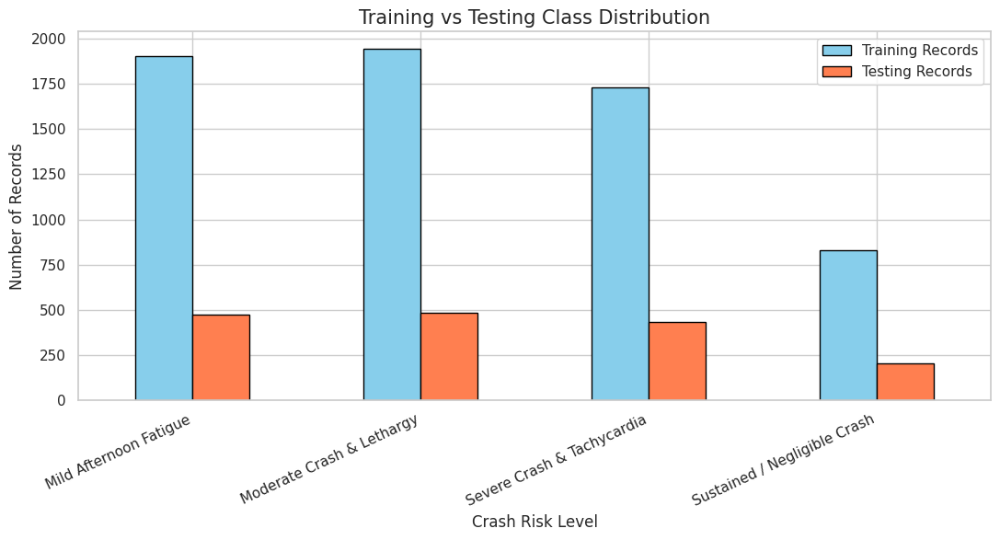


PREPROCESSING CONFIGURATION READY

TOTAL ML ALGORITHMS: 8

TRAINING: Logistic Regression
Accuracy : 72.06 %
Precision: 72.35 %
Recall   : 72.06 %
F1 Score : 72.16 %
ROC-AUC  : 92.04 %

TRAINING: Decision Tree
Accuracy : 68.31 %
Precision: 69.17 %
Recall   : 68.31 %
F1 Score : 68.52 %
ROC-AUC  : 86.39 %

TRAINING: Random Forest
Accuracy : 75.75 %
Precision: 76.54 %
Recall   : 75.75 %
F1 Score : 75.96 %
ROC-AUC  : 93.52 %

TRAINING: KNN
Accuracy : 64.56 %
Precision: 66.23 %
Recall   : 64.56 %
F1 Score : 64.91 %
ROC-AUC  : 85.93 %

TRAINING: Support Vector Machine
Accuracy : 76.88 %
Precision: 77.41 %
Recall   : 76.88 %
F1 Score : 77.03 %
ROC-AUC  : 94.4 %

TRAINING: Gradient Boosting
Accuracy : 76.38 %
Precision: 77.02 %
Recall   : 76.38 %
F1 Score : 76.51 %
ROC-AUC  : 93.81 %

TRAINING: Extra Trees
Accuracy : 74.75 %
Precision: 75.58 %
Recall   : 74.75 %
F1 Score : 74.89 %
ROC-AUC  : 93.07 %

TRAINING: Hist Gradient Boosting
Accuracy : 78.5 %
Precision: 78.87 %
Recall   : 78.5 %
F1 Sco

,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%)
0,Hist Gradient Boosting,78.500,78.870,78.500,78.600,94.460
1,Support Vector Machine,76.880,77.410,76.880,77.030,94.400
2,Gradient Boosting,76.380,77.020,76.380,76.510,93.810
3,Random Forest,75.750,76.540,75.750,75.960,93.520
4,Extra Trees,74.750,75.580,74.750,74.890,93.070
5,Logistic Regression,72.060,72.350,72.060,72.160,92.040
6,Decision Tree,68.310,69.170,68.310,68.520,86.390
7,KNN,64.560,66.230,64.560,64.910,85.930


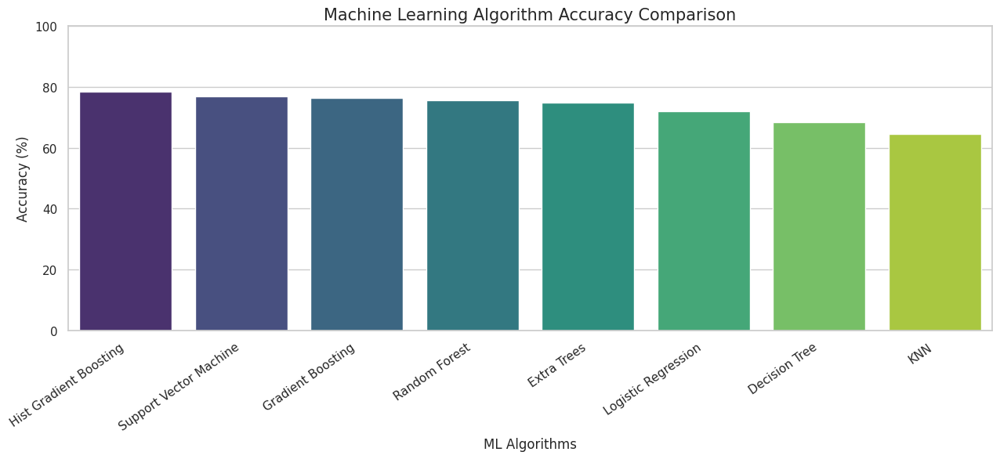

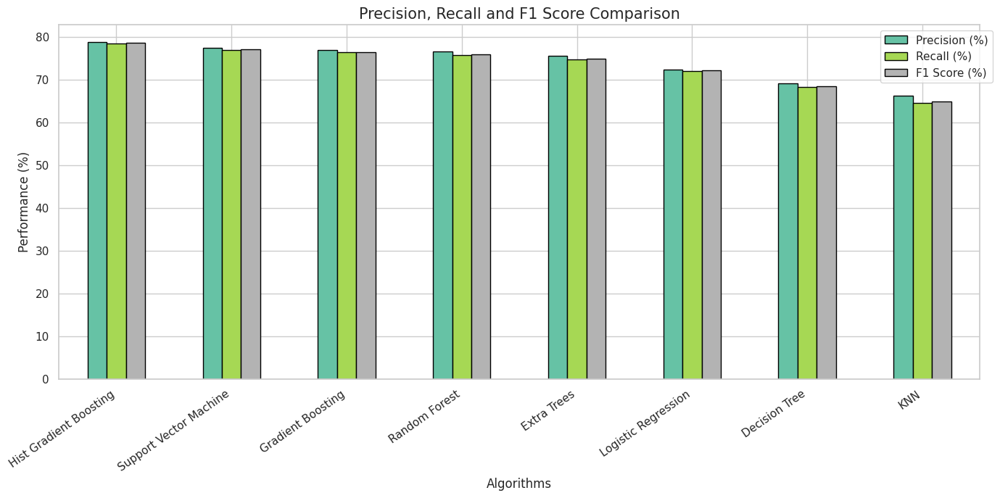

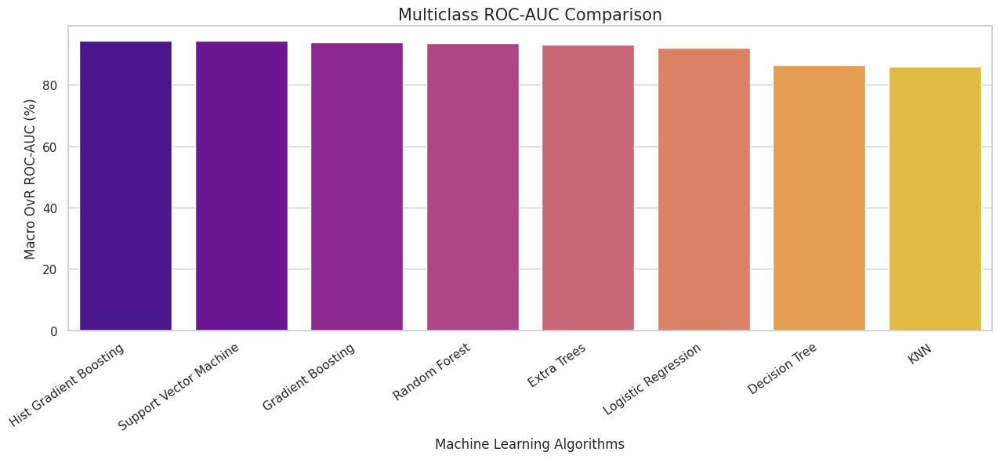


BEST MODEL: Hist Gradient Boosting
BEST ACCURACY: 78.5 %
BEST ROC-AUC: 94.46 %

BEST MODEL CLASSIFICATION REPORT
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.77      0.74      0.75       476
   Moderate Crash & Lethargy       0.71      0.79      0.75       485
  Severe Crash & Tachycardia       0.89      0.84      0.86       432
Sustained / Negligible Crash       0.81      0.78      0.79       207

                    accuracy                           0.79      1600
                   macro avg       0.79      0.79      0.79      1600
                weighted avg       0.79      0.79      0.79      1600



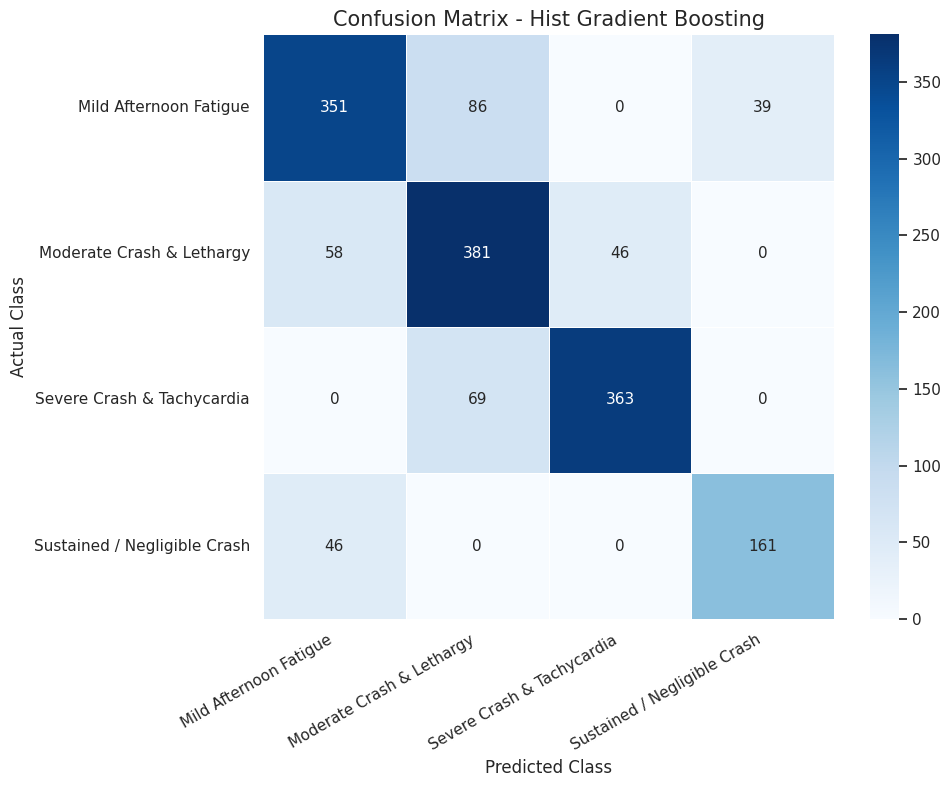

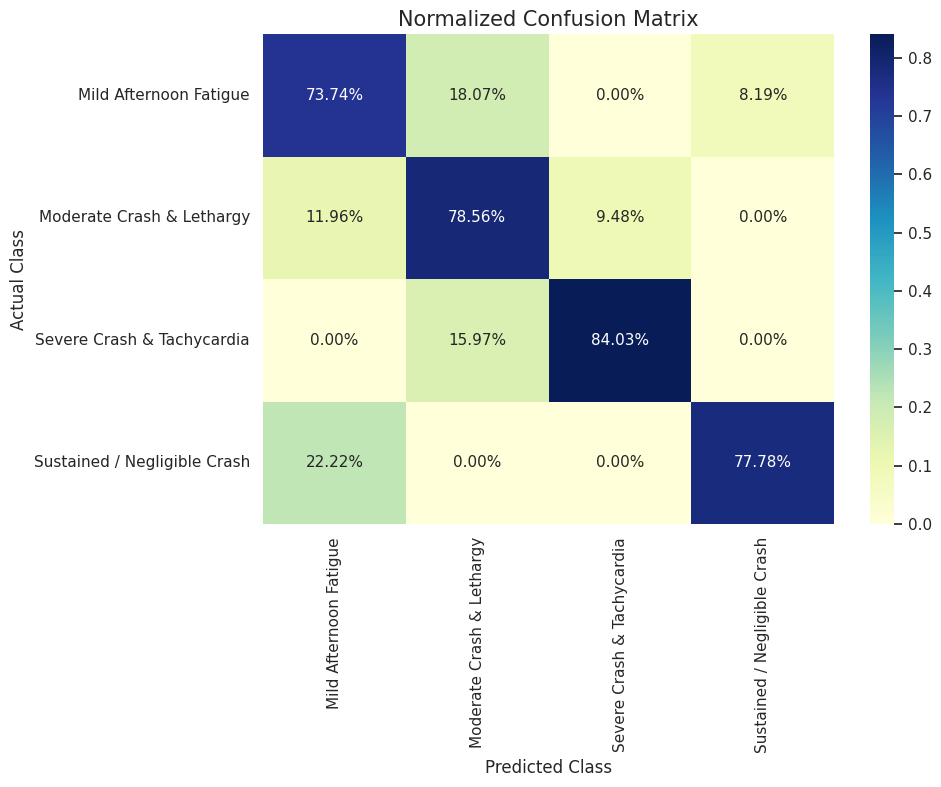

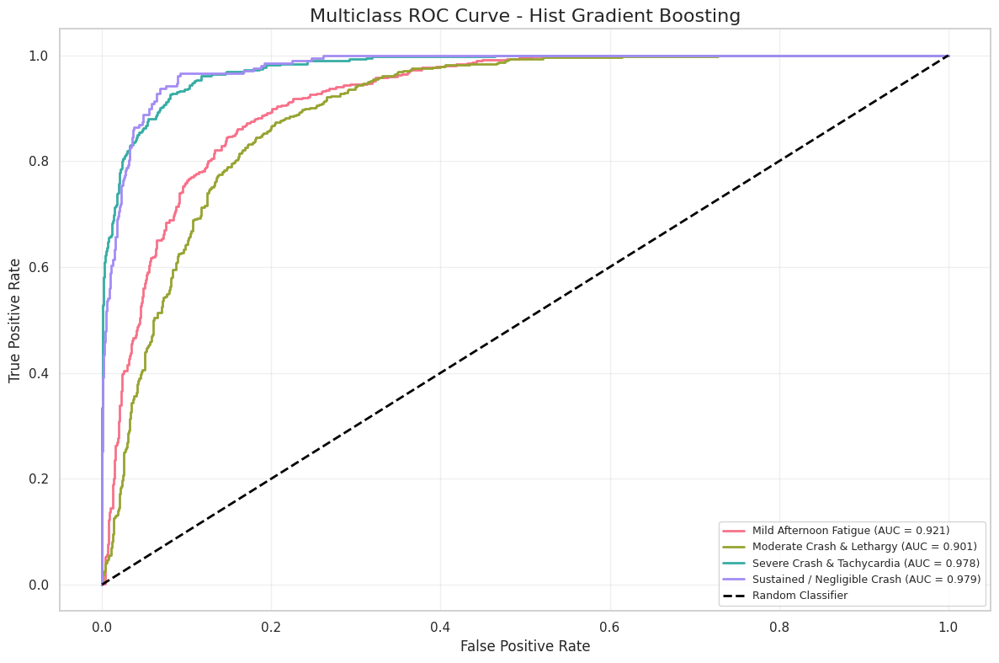

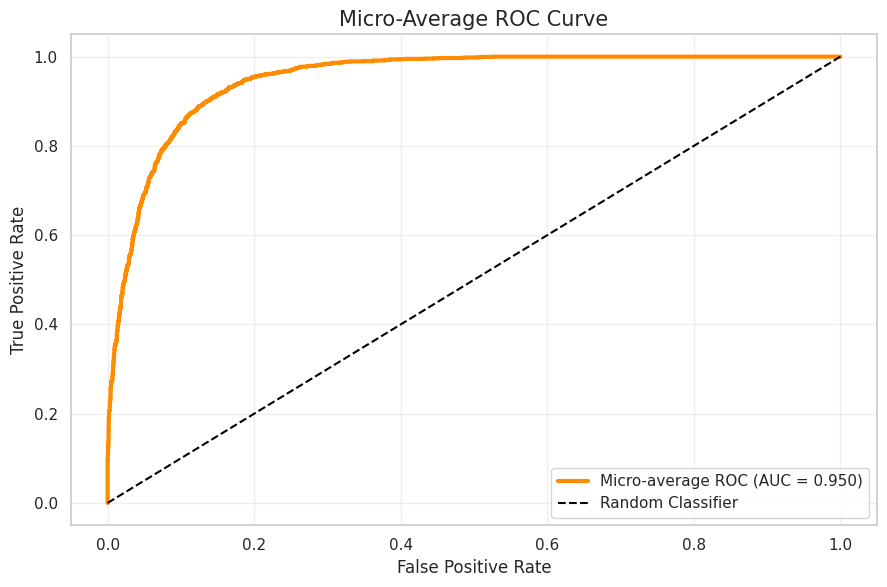

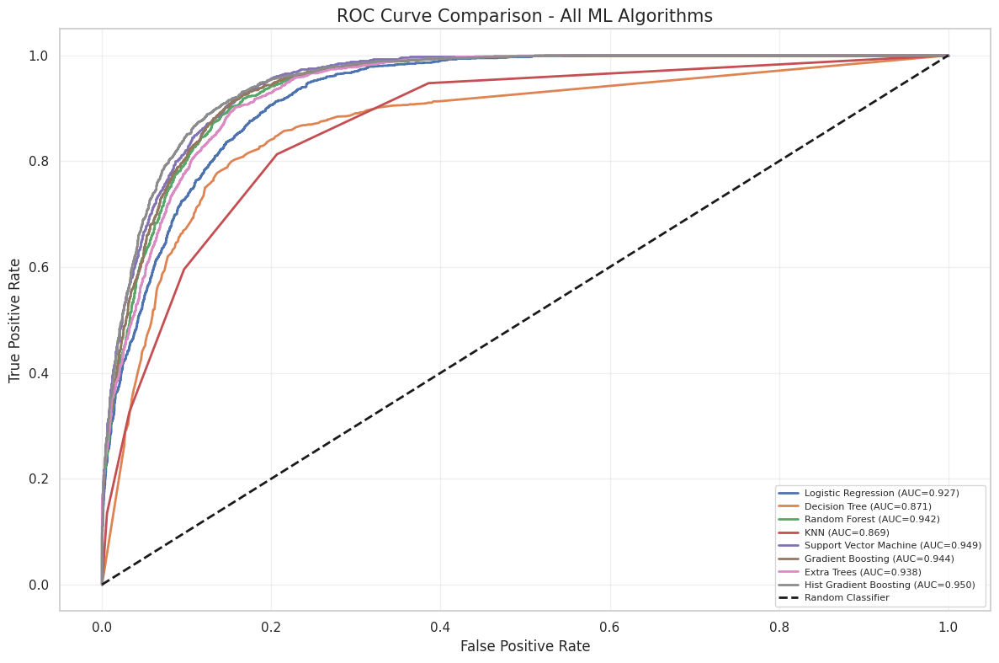

Best model does not provide built-in feature importance.

          FINAL MACHINE LEARNING REPORT

Dataset Records: 8000
Total Features Used: 11
Training Records: 6400
Testing Records: 1600
Number of Classes: 4

BEST ALGORITHM: Hist Gradient Boosting
ACCURACY: 78.5 %
PRECISION: 78.87 %
RECALL: 78.5 %
F1 SCORE: 78.6 %
ROC-AUC: 94.46 %

MODEL COMPARISON


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%)
0,Hist Gradient Boosting,78.500,78.870,78.500,78.600,94.460
1,Support Vector Machine,76.880,77.410,76.880,77.030,94.400
2,Gradient Boosting,76.380,77.020,76.380,76.510,93.810
3,Random Forest,75.750,76.540,75.750,75.960,93.520
4,Extra Trees,74.750,75.580,74.750,74.890,93.070
5,Logistic Regression,72.060,72.350,72.060,72.160,92.040
6,Decision Tree,68.310,69.170,68.310,68.520,86.390
7,KNN,64.560,66.230,64.560,64.910,85.930



MACHINE LEARNING COMPLETED SUCCESSFULLY!


In [9]:

# ================================================================
# COMPLETE MACHINE LEARNING CLASSIFICATION
# CAFFEINE CRASH, JITTERS, ENERGY DRINKS AND ANXIETY DATASET
# TRAIN TEST SPLIT + LABEL ENCODING + ML ALGORITHMS + ROC CURVE
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

sns.set_style('whitegrid')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42


# ================================================================
# 2. LOAD DATASET
# ================================================================

df_raw = pd.read_csv(
    '/kaggle/input/datasets/samartalwar/caffeine-crash-and-jitters-energy-drinks-and-anxiety/caffeine_crash_and_anxiety_telemetry.csv'
)

print("DATASET SHAPE:", df_raw.shape)

display(df_raw.head())


# ================================================================
# 3. DATASET INFORMATION
# ================================================================

print("\nDATASET INFORMATION")

print(df_raw.info())

print("\nMISSING VALUES")

print(df_raw.isnull().sum())

print("\nDUPLICATE RECORDS")

print(df_raw.duplicated().sum())

print("\nTARGET DISTRIBUTION")

display(df_raw['crash_risk_level'].value_counts())


# ================================================================
# 4. DATA CLEANING
# ================================================================

df_raw = df_raw.drop_duplicates().copy()

# Remove rows where target is missing
df_raw = df_raw.dropna(
    subset=['crash_risk_level']
).copy()

print("\nCLEANED DATASET SHAPE:", df_raw.shape)


# ================================================================
# 5. DEFINE TARGET VARIABLE
# ================================================================

target = 'crash_risk_level'

print("\nTARGET VARIABLE:", target)

print("\nTARGET CLASSES")

print(df_raw[target].unique())


# ================================================================
# 6. FEATURE SELECTION
# ================================================================

# Exclude user_id because it is an identifier.
# Exclude post-consumption response measurements to reduce
# the risk of target leakage in prospective risk prediction.

post_outcome_features = [
    'heart_rate_spike_bpm',
    'jitters_intensity_score',
    'acute_anxiety_score',
    'crash_onset_hours',
    'crash_severity_score'
]

# Use pre-consumption / consumption-related predictors
feature_cols = [
    col for col in df_raw.columns
    if col not in (
        ['user_id', target] + post_outcome_features
    )
]

X = df_raw[feature_cols].copy()

y = df_raw[target].copy()

print("\nSELECTED FEATURES")

print(feature_cols)

print("\nTOTAL FEATURES:", len(feature_cols))

print("\nTARGET VARIABLE:", target)


# ================================================================
# 7. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ================================================================

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("\nNUMERICAL FEATURES")

print(numeric_features)

print("\nCATEGORICAL FEATURES")

print(categorical_features)


# ================================================================
# 8. LABEL ENCODING OF TARGET VARIABLE
# ================================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y.astype(str))

class_names = label_encoder.classes_

num_classes = len(class_names)

print("\nTARGET LABEL ENCODING")

for i, class_name in enumerate(class_names):

    print(class_name, "=", i)

print("\nTOTAL TARGET CLASSES:", num_classes)


# ================================================================
# 9. TRAIN TEST SPLITTING
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print("\nTRAIN TEST SPLIT COMPLETED")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTRAINING DATA:", len(X_train))
print("TESTING DATA:", len(X_test))


# ================================================================
# 10. CHECK CLASS DISTRIBUTION
# ================================================================

train_distribution = pd.Series(y_train).value_counts().sort_index()

test_distribution = pd.Series(y_test).value_counts().sort_index()

distribution_df = pd.DataFrame({
    'Class': class_names,
    'Training Records': train_distribution.values,
    'Testing Records': test_distribution.values
})

print("\nCLASS DISTRIBUTION")

display(distribution_df)

distribution_df.set_index('Class').plot(
    kind='bar',
    figsize=(11, 6),
    color=['skyblue', 'coral'],
    edgecolor='black'
)

plt.title("Training vs Testing Class Distribution")
plt.xlabel("Crash Risk Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=25, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


# ================================================================
# 11. PREPROCESSING AND LABEL ENCODING
# ================================================================

# Numerical data:
# Missing value imputation + standard scaling

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Categorical data:
# Missing value imputation + ordinal label encoding

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'encoder',
            OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("\nPREPROCESSING CONFIGURATION READY")


# ================================================================
# 12. DEFINE MACHINE LEARNING ALGORITHMS
# ================================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=RANDOM_STATE
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Support Vector Machine': SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=RANDOM_STATE
    )

}

print("\nTOTAL ML ALGORITHMS:", len(models))


# ================================================================
# 13. TRAIN ALL MACHINE LEARNING MODELS
# ================================================================

trained_models = {}

results = []

roc_results = {}

predictions = {}

for model_name, model in models.items():

    print("\n" + "=" * 65)

    print("TRAINING:", model_name)

    print("=" * 65)

    try:

        # Create pipeline
        pipeline = Pipeline(
            steps=[
                ('preprocessor', preprocessor),
                ('classifier', model)
            ]
        )

        # Train model
        pipeline.fit(X_train, y_train)

        # Predict test data
        y_pred = pipeline.predict(X_test)

        # Predict probabilities for ROC curve
        y_prob = pipeline.predict_proba(X_test)

        # Evaluation metrics
        accuracy = accuracy_score(
            y_test,
            y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            average='weighted',
            zero_division=0
        )

        # Multiclass ROC-AUC
        roc_auc = roc_auc_score(
            y_test,
            y_prob,
            multi_class='ovr',
            average='macro',
            labels=np.arange(num_classes)
        )

        # Store trained model
        trained_models[model_name] = pipeline

        predictions[model_name] = y_pred

        roc_results[model_name] = y_prob

        results.append({

            'Algorithm': model_name,

            'Accuracy (%)': accuracy * 100,

            'Precision (%)': precision * 100,

            'Recall (%)': recall * 100,

            'F1 Score (%)': f1 * 100,

            'ROC-AUC (%)': roc_auc * 100

        })

        print("Accuracy :", round(accuracy * 100, 2), "%")

        print("Precision:", round(precision * 100, 2), "%")

        print("Recall   :", round(recall * 100, 2), "%")

        print("F1 Score :", round(f1 * 100, 2), "%")

        print("ROC-AUC  :", round(roc_auc * 100, 2), "%")

    except Exception as e:

        print("MODEL FAILED:", model_name)

        print("ERROR:", str(e))


# ================================================================
# 14. MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(results)

if results_df.empty:

    raise ValueError(
        "All models failed. Check the preprocessing and dataset."
    )

results_df = results_df.sort_values(
    by='Accuracy (%)',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)

print("MACHINE LEARNING MODEL COMPARISON")

print("=" * 65)

display(
    results_df.round(2)
)


# ================================================================
# 15. ACCURACY COMPARISON GRAPH
# ================================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Accuracy (%)',
    hue='Algorithm',
    palette='viridis',
    legend=False
)

plt.title("Machine Learning Algorithm Accuracy Comparison")

plt.xlabel("ML Algorithms")

plt.ylabel("Accuracy (%)")

plt.xticks(rotation=35, ha='right')

plt.ylim(0, 100)

plt.tight_layout()

plt.show()


# ================================================================
# 16. PRECISION, RECALL AND F1 SCORE COMPARISON
# ================================================================

metric_columns = [
    'Precision (%)',
    'Recall (%)',
    'F1 Score (%)'
]

results_df.set_index('Algorithm')[metric_columns].plot(
    kind='bar',
    figsize=(14, 7),
    colormap='Set2',
    edgecolor='black'
)

plt.title("Precision, Recall and F1 Score Comparison")

plt.xlabel("Algorithms")

plt.ylabel("Performance (%)")

plt.xticks(rotation=35, ha='right')

plt.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()

plt.show()


# ================================================================
# 17. ROC-AUC COMPARISON GRAPH
# ================================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='ROC-AUC (%)',
    hue='Algorithm',
    palette='plasma',
    legend=False
)

plt.title("Multiclass ROC-AUC Comparison")

plt.xlabel("Machine Learning Algorithms")

plt.ylabel("Macro OvR ROC-AUC (%)")

plt.xticks(rotation=35, ha='right')

plt.tight_layout()

plt.show()


# ================================================================
# 18. SELECT BEST MODEL
# ================================================================

best_model_name = results_df.iloc[0]['Algorithm']

best_model = trained_models[best_model_name]

print("\nBEST MODEL:", best_model_name)

print(
    "BEST ACCURACY:",
    round(results_df.iloc[0]['Accuracy (%)'], 2),
    "%"
)

print(
    "BEST ROC-AUC:",
    round(results_df.iloc[0]['ROC-AUC (%)'], 2),
    "%"
)


# ================================================================
# 19. CLASSIFICATION REPORT
# ================================================================

best_predictions = predictions[best_model_name]

print("\nBEST MODEL CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        best_predictions,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    )
)


# ================================================================
# 20. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.title(f"Confusion Matrix - {best_model_name}")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.xticks(rotation=30, ha='right')

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()


# ================================================================
# 21. NORMALIZED CONFUSION MATRIX
# ================================================================

cm_normalized = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(num_classes),
    normalize='true'
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt='.2%',
    cmap='YlGnBu',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Normalized Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.tight_layout()

plt.show()


# ================================================================
# 22. MULTICLASS ROC CURVES - BEST MODEL
# ================================================================

best_probabilities = roc_results[best_model_name]

# Binarize actual target classes
y_test_binary = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

plt.figure(figsize=(12, 8))

colors = sns.color_palette(
    'husl',
    num_classes
)

for i, color in enumerate(colors):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        best_probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f'{class_names[i]} (AUC = {class_auc:.3f})'
    )

# No-skill reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    linewidth=2,
    label='Random Classifier'
)

plt.title(
    f"Multiclass ROC Curve - {best_model_name}",
    fontsize=16
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ================================================================
# 23. MICRO-AVERAGE ROC CURVE
# ================================================================

micro_fpr, micro_tpr, _ = roc_curve(
    y_test_binary.ravel(),
    best_probabilities.ravel()
)

micro_auc = auc(
    micro_fpr,
    micro_tpr
)

plt.figure(figsize=(9, 6))

plt.plot(
    micro_fpr,
    micro_tpr,
    color='darkorange',
    linewidth=3,
    label=f'Micro-average ROC (AUC = {micro_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title("Micro-Average ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(loc='lower right')

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ================================================================
# 24. ROC CURVES FOR ALL MODELS
# ================================================================

plt.figure(figsize=(12, 8))

for model_name, probabilities in roc_results.items():

    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        probabilities.ravel()
    )

    model_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{model_name} (AUC={model_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    linewidth=2,
    label='Random Classifier'
)

plt.title("ROC Curve Comparison - All ML Algorithms")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(
    loc='lower right',
    fontsize=8
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ================================================================
# 25. FEATURE IMPORTANCE - TREE BASED BEST MODEL
# ================================================================

best_classifier = best_model.named_steps['classifier']

if hasattr(best_classifier, 'feature_importances_'):

    feature_names = (
        best_model
        .named_steps['preprocessor']
        .get_feature_names_out()
    )

    importance_df = pd.DataFrame({

        'Feature': feature_names,

        'Importance': best_classifier.feature_importances_

    })

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    )

    print("\nFEATURE IMPORTANCE")

    display(importance_df.head(20))

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=importance_df.head(20),
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='viridis',
        legend=False
    )

    plt.title("Top 20 Important Features")

    plt.xlabel("Importance Score")

    plt.ylabel("Features")

    plt.tight_layout()

    plt.show()

else:

    print(
        "Best model does not provide built-in feature importance."
    )


# ================================================================
# 26. FINAL MODEL PERFORMANCE REPORT
# ================================================================

print("\n" + "=" * 70)

print("          FINAL MACHINE LEARNING REPORT")

print("=" * 70)

print("\nDataset Records:", len(df_raw))

print("Total Features Used:", len(feature_cols))

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("Number of Classes:", num_classes)

print("\nBEST ALGORITHM:", best_model_name)

print(
    "ACCURACY:",
    round(
        accuracy_score(y_test, best_predictions) * 100,
        2
    ),
    "%"
)

print(
    "PRECISION:",
    round(
        precision_score(
            y_test,
            best_predictions,
            average='weighted',
            zero_division=0
        ) * 100,
        2
    ),
    "%"
)

print(
    "RECALL:",
    round(
        recall_score(
            y_test,
            best_predictions,
            average='weighted',
            zero_division=0
        ) * 100,
        2
    ),
    "%"
)

print(
    "F1 SCORE:",
    round(
        f1_score(
            y_test,
            best_predictions,
            average='weighted',
            zero_division=0
        ) * 100,
        2
    ),
    "%"
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            best_probabilities,
            multi_class='ovr',
            average='macro'
        ) * 100,
        2
    ),
    "%"
)

print("\nMODEL COMPARISON")

display(results_df.round(2))

print("\nMACHINE LEARNING COMPLETED SUCCESSFULLY!")

print("=" * 70)


## Thank you..pls upvote!!!!!!!!!